# MNIST HVO2 类别区域编码网络：为 OOD 实验准备

## 0. 全局参数配置

当前未知数字为1，ID数字为0及2–9。只需修改第0部分的`EXCLUDED_DIGITS`，ID列表自动取补集，标签映射、类别原型与图例同步更新。合并MNIST官方两个分区后，所有参与数字随机下采样到最少类别数量，再逐类划分90%候选/10%测试；图像保持原始28×28灰度。

网络为 **784 个 HVO2 输入器件 → 441 个 HVO2 隐藏器件 → 9 维线性分类头**。输入灰度保持 6.3–7.5 mA；隐藏层默认扩展为 6.3–10 mA，上限可配置到 10 mA 以上。低于一个完整周期的响应没有可观测脉冲输出。

借鉴 TAC 的预设类别编码思想，对真实隐藏器件施加软约束：对应类别区域振荡更久，区域外尽量不足一个脉冲。默认九个固定 7×7 区域，每类49个，可配置为45–53个且总数保持441。训练完成后用训练集类别均值及余弦相似度检测OOD，不引入SAE。90%训练候选分区中再留出1/9独立校准，使训练∶校准∶测试约为8∶1∶1（每类计数向下取整）。10%测试集不参与原型或阈值选择。默认只用独立ID校准分数确定阈值，先验目标为让80%的ID通过检测。未知数字仅用于最终OOD测试，不参加网络训练、类别原型计算或阈值选择。每个ID类别的训练/校准/测试数量分别相同；最终每个未知标签与单个ID测试标签等量，9个ID加1个未知时，未知恰占10%。

依赖、网络参数、器件参数、区域编码和损失参数都在下方。运行依赖 `numpy`、`matplotlib`、`torch`、`scikit-learn`，复用现有神经元源码及本地 MNIST 数据。修改参数后请从头运行。


In [1]:
# 所有依赖导入
import gzip
import importlib.util
import math
import random
import struct
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, roc_curve


# 路径定位：支持从仓库根目录、HVO2 或 ODD 目录启动 notebook
def find_hvo2_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / 'HVO2'):
            if (candidate / 'finite_oscillation_model.py').is_file():
                return candidate.resolve()
    raise FileNotFoundError('无法定位 HVO2；请从项目根目录、HVO2 或 ODD 目录启动。')


HVO2_ROOT = find_hvo2_root()
PROJECT_DIR = HVO2_ROOT / 'ODD'                 # 当前实验目录（按用户指定命名为 ODD）
MNIST_DIR = HVO2_ROOT / 'data' / 'MNIST' / 'raw'  # MNIST 原始 IDX 数据目录
NEURON_KIND = 'HVO2'                           # 神经元种类；本版实现 HVO2
NEURON_MODULE_PATH = HVO2_ROOT / 'finite_oscillation_model.py'  # 神经元导入路径

# 数据与网络结构
EXCLUDED_DIGITS = (1,)                         # 未知/OOD数字；更换此处后ID列表自动取其补集
TRAIN_DIGITS = tuple(d for d in range(10) if d not in EXCLUDED_DIGITS)  # ID数字，当前为0、2–9
TRAIN_RATIO = 0.9                              # 训练+校准总分区比例；其余10%保留为测试
IMAGE_SHAPE = (28, 28)                         # 图像高、宽；需与 IDX 实际形状一致
INPUT_DIM = 784                                # 输入层神经元数；必须等于图像像素数
HIDDEN_DIM = 441                               # 隐藏层神经元数，21×21，便于后续按 9 类划分
HIDDEN_GRID_SHAPE = (21, 21)                    # 隐藏层热力图行、列；乘积必须等于 HIDDEN_DIM
OUTPUT_DIM = len(TRAIN_DIGITS)                  # 输出维数，当前9；必须等于ID类别数
USE_BIAS = True                                # 两个全连接层是否使用偏置（参考文件默认开启）

# 训练设置：除 epoch 数和固定随机种子外沿用参考 notebook 默认值
RANDOM_SEED = 306879214                         # 创建时随机抽取并固定；重复运行不重新抽取
BALANCE_SEED = RANDOM_SEED + 17                 # 各数字等量下采样种子；同一数字不因ID/OOD角色切换而改变
EPOCHS = 5                                     # 训练轮数
BATCH_SIZE = 32                                # 批大小
LEARNING_RATE = 1e-3                           # AdamW 学习率：学习连接权重、偏置和隐藏层电流映射
WEIGHT_DECAY = 1e-4                            # AdamW 权重衰减
NUM_WORKERS = 0                                # 数据加载子进程数；Windows notebook 默认 0
DEVICE_PREFERENCE = 'auto'                      # 计算设备：auto / cpu / cuda
RUN_TRAINING = True                            # 是否执行第 2 部分训练
TRAIN_LIMIT = None                             # 调试训练样本上限；None 使用全部训练样本
TEST_LIMIT = None                              # 调试测试样本上限；None 使用全部测试样本

# 分层电流映射；输入层保持原映射，隐藏层上限支持调整到 10 mA 以上
CURRENT_MIN_MA = 6.3                            # 输入层灰度映射电流下限（mA）
CURRENT_MAX_MA = 7.5                            # 输入层灰度映射电流上限（mA）
HIDDEN_CURRENT_MIN_MA = 6.3                     # 隐藏层电流下限（mA）
HIDDEN_CURRENT_MAX_MA = 10.0                    # 隐藏层电流上限（mA）；可设为 10.5、11 等
MAPPER_OFFSET_INIT = 0.0                        # 每神经元可学习电流映射偏移初值
MAPPER_SCALE_INIT = 1.0                         # softplus(raw_scale) 初值
MAPPER_SCALE_FLOOR = 0.05                       # 映射尺度附加下限
MIN_COMPLETE_CYCLES = 1.0                      # 至少一个完整周期才有可观测脉冲输出
PULSE_GATE_TEMPERATURE = 0.5                    # log(周期数) 上的脉冲门控代理梯度温度

# TAC 思想的类别区域软约束；这不是原论文多层投影 TAC 的直接复现
CLASS_GRID_SHAPE = (3, 3)                      # 类别区域排列；默认九个 7×7 块
CLASS_REGION_SIZES = (49,) * 9                  # 每类预分配数量，可不相等；总数须为 441
CLASS_REGION_SIZE_TOLERANCE = 0.10              # 预分配大小相对均分值的容差；严格整数 45–53
TAC_LOSS_WEIGHT = 0.1                          # 类别区域约束损失权重
TAC_WARMUP_EPOCHS = 2                          # 损失权重线性升到设定值所需轮数
TAC_ON_TARGET_MS = 40.0                        # 目标区域鼓励至少持续的振荡时间（ms）
TAC_OFF_TARGET_CYCLES = 0.5                    # 区域外鼓励不超过的周期数，低于一个完整脉冲
LONG_RESPONSE_THRESHOLD_MS = 10.0              # 统计“长响应”数量的阈值；不是区域预算
TAC_EPS = 1e-12                               # 对数计算数值下限
CLASS_HEATMAP_FIGSIZE = (13, 11)                # 每轮九类样本与最终九类平均时长图尺寸

# 余弦 OOD：仅在训练完成后建立原型、校准及评估，不引入 SAE
OOD_CALIBRATION_RATIO = 1 / 9                  # 90%候选分区中留1/9校准；总训练∶校准∶测试≈8∶1∶1
OOD_SPLIT_SEED = RANDOM_SEED + 101              # 校准划分种子，校准仅从训练候选分区抽取
OOD_SAMPLE_SEED = RANDOM_SEED + 202             # 排除数字抽样和混合顺序种子
OOD_ID_RETENTION = 0.80                        # 先验目标：让80%的校准ID通过检测；不读取未知样本
OOD_COSINE_THRESHOLD = None                    # None：按规则校准；设置[0,1]数值优先手动覆盖
OOD_COSINE_EPS = 1e-12                         # L2归一化数值下限，全零响应相似度为0
OOD_HIST_BINS = 40                             # ID/未知余弦分数分布直方图分箱数
OOD_PREVIEW_ROWS = 20                          # 控制台预览样本数；全部分数保存在ood_results中

# 固定器件拟合参数：对应参考文件和 finite_oscillation_model.py；不参与训练
HVO2_THRESHOLD_MA = 4.55                        # 起振电流阈值（mA）
HVO2_KNEE_MA = 6.099924                         # 振荡持续时间曲线拐点（mA）
HVO2_REF_CURRENT_MA = 7.32                      # 频率拟合参考电流（mA）
HVO2_REF_FREQ_HZ = 21643.2670724                 # 频率拟合参考频率（Hz）
HVO2_FREQ_SLOPE_HZ_PER_MA = 420.87232            # 频率对电流斜率（Hz/mA）
HVO2_MIN_FREQ_HZ = 1.0                          # 起振后的最小频率（Hz）
HVO2_DURATION_LOW_MS = 90.0                     # 拐点以下的振荡持续时间（ms）
HVO2_DURATION_A1_MS = 79.4                      # 持续时间拟合第一项幅度（ms）
HVO2_DURATION_W1_MA = 0.2613                    # 持续时间拟合第一项电流宽度（mA）
HVO2_DURATION_A2_MS = 10.6                      # 持续时间拟合第二项幅度（ms）
HVO2_DURATION_W2_MA = 1.2998                    # 持续时间拟合第二项电流宽度（mA）
HVO2_DT_MS = 0.01                              # 停振时间离散化步长（ms），采用直通梯度
HVO2_DETECTOR_MS = 0.0001                       # 停振后检测并提交结果的延迟（ms）
HVO2_INITIAL_H = 0.0                            # 每张图独立仿真、器件从完全恢复状态开始；本版固定为 0

# 活动可视化；图像起始时刻为 global time = 0，输出层是线性层，不画振荡曲线
ACTIVITY_SAMPLE_ID = 0                          # 固定的分布内测试样本索引，0 表示第 1 个
ACTIVITY_TIME_POINTS = 401                      # 基础时间网格点数；另加入精确启动/停振边界
ACTIVITY_END_MS = None                          # 时间轴终点（ms）；None 自动覆盖两层完整活动范围
ACTIVITY_FIGSIZE = (11, 3.5)                    # 每轮活动图尺寸
HEATMAP_SAMPLE_OCCURRENCE = 'mean'                  # 正整数：各标签第几次出现；'mean'：全部同类测试样本均值
HEATMAP_CMAP = 'viridis'                       # 振荡时长热力图配色
HEATMAP_VMIN_MS = 0.0                          # 统一色标下限（ms）
HEATMAP_VMAX_MS = None                         # 统一色标上限；None 使用当前电流范围最大离散时长


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


if DEVICE_PREFERENCE not in ('auto', 'cpu', 'cuda'):
    raise ValueError('DEVICE_PREFERENCE 必须为 auto / cpu / cuda')
DEVICE = torch.device(
    'cuda' if DEVICE_PREFERENCE == 'auto' and torch.cuda.is_available()
    else 'cpu' if DEVICE_PREFERENCE == 'auto' else DEVICE_PREFERENCE
)
seed_everything(RANDOM_SEED)
print(f'设备: {DEVICE} | 固定随机种子: {RANDOM_SEED}')
print(f'实验目录: {PROJECT_DIR}\nMNIST 目录: {MNIST_DIR}')


设备: cuda | 固定随机种子: 306879214
实验目录: E:\finate_response\HVO2\ODD
MNIST 目录: E:\finate_response\HVO2\data\MNIST\raw


## 1. 网络架构

输入和连接结构沿用前版；隐藏器件电流范围和输出读法作如下扩展。器件频率/持续时间拟合保持固定，导入 `finite_oscillation_model.py` 核对连续公式。高电流区使用原公式外推，尚不等同于该区间已经过硬件测量验证。

- **输入层**：原始灰度 `/255` 后映射到 6.3–7.5 mA，采用原参考的频率归一化，保留输入动态范围。
- **隐藏层**：全连接后以可学习 sigmoid 电流映射到默认 6.3–10 mA。`频率×连续寿命` 不足一个完整周期时，无可观测脉冲。判据在时间网格取整前计算，不能因取整制造一个脉冲。
- **分类特征**：有完整脉冲时使用 `原始频率 / 隐藏层上限参考频率`，无完整脉冲时为0。采用绝对频率比，避免把 6.3 mA 的长振荡错误地归零；分类头仍为线性441→9。前向采用严格脉冲判据，门控反向使用平滑代理梯度。
- **时序**：隐藏层仍等待全部输入就绪；按连续寿命向上取整、加停振检测延迟。无完整脉冲的亚周期瞬态仍有内部寿命和提交时间，但不计作可观测振荡活动。此模型不模拟逐脉冲波形。
- **固定类别编码**：默认21×21网格分为九个7×7块，按`TRAIN_DIGITS`顺序（当前0、2–9）从左上到右下排列。每类预分配49个；允许手动设定不等大小45–53，总数保持441。不同大小配置从超额区域向不足区域转让邻近网格点，所有编码固定、互不重叠。
- **软损失**：`L = L分类交叉熵 + λ × L区域`。区域内对不足40 ms的寿命施加对数尺度平方惩罚；区域外对超过0.5个周期的响应施加对数尺度平方惩罚，两部分分别按各自区域大小平均。λ默认0.1，前两轮线性升高。允许真实响应少量偏移；45–53限制的是预分配区域大小，不是强制每张图的活动数量。

这是借鉴 TAC 类别编码思想、直接约束真实器件响应的适配。未添加投影层，也未冻结主网络；推理前向不接收标签，不按真实类别筛选神经元。TAC原文与作者代码链接记录于 `OOD_CONTEXT.md`。


每轮热力图模式: 各标签全部分布内测试样本的平均响应（mean）
标签映射（输出索引 → 实际数字）: {0: 0, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8, 8: 9}
各数字原始数量: {0: 6903, 1: 7877, 2: 6990, 3: 7141, 4: 6824, 5: 6313, 6: 6876, 7: 7293, 8: 6825, 9: 6958}
等量下采样：每类 6313 张；训练/校准/测试各分区内类别数量相同。
每类数量：digit | balanced pool | train+cal | fit | calibration | ID test | held-out OOD test
           0 |          6313 |      5681 | 5050 |         631 |     632 |                 0
           1 |          6313 |         0 |    0 |           0 |       0 |               632
           2 |          6313 |      5681 | 5050 |         631 |     632 |                 0
           3 |          6313 |      5681 | 5050 |         631 |     632 |                 0
           4 |          6313 |      5681 | 5050 |         631 |     632 |                 0
           5 |          6313 |      5681 | 5050 |         631 |     632 |                 0
           6 |          6313 |      5681 | 5050 |         631 |     632 |                 0
           7 |          

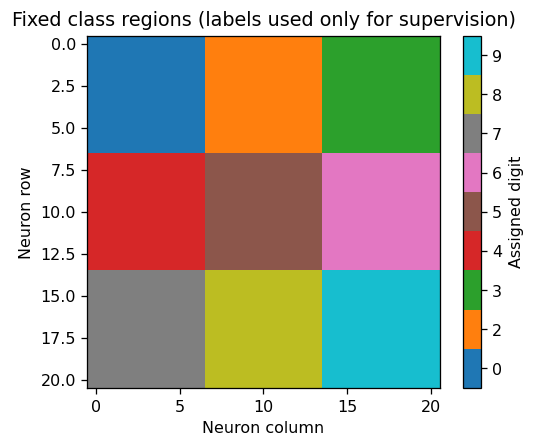

In [2]:
def validate_configuration():
    if NEURON_KIND.upper() != 'HVO2':
        raise ValueError('本版仅支持 HVO2；更换种类时需要实现对应可微适配器。')
    if not TRAIN_DIGITS or len(set(TRAIN_DIGITS)) != len(TRAIN_DIGITS):
        raise ValueError('TRAIN_DIGITS 必须非空且不能包含重复数字。')
    if len(set(EXCLUDED_DIGITS)) != len(EXCLUDED_DIGITS):
        raise ValueError('EXCLUDED_DIGITS 不能包含重复数字。')
    if any(not isinstance(d, int) or d not in range(10) for d in (*TRAIN_DIGITS, *EXCLUDED_DIGITS)):
        raise ValueError('MNIST 数字必须是 0 到 9 的整数。')
    if set(TRAIN_DIGITS) & set(EXCLUDED_DIGITS):
        raise ValueError('训练数字和排除数字不能重叠。')
    if tuple(IMAGE_SHAPE) != (28, 28) or INPUT_DIM != math.prod(IMAGE_SHAPE):
        raise ValueError('MNIST 原图为 28×28，INPUT_DIM 必须等于图像像素数 784。')
    if (len(HIDDEN_GRID_SHAPE) != 2
            or any(not isinstance(n, int) or n < 1 for n in HIDDEN_GRID_SHAPE)
            or math.prod(HIDDEN_GRID_SHAPE) != HIDDEN_DIM):
        raise ValueError('HIDDEN_GRID_SHAPE 必须是两个正整数，且乘积等于 HIDDEN_DIM。')
    if OUTPUT_DIM != len(TRAIN_DIGITS):
        raise ValueError('OUTPUT_DIM 必须等于 TRAIN_DIGITS 的类别数量。')
    for name, value in dict(INPUT_DIM=INPUT_DIM, HIDDEN_DIM=HIDDEN_DIM, OUTPUT_DIM=OUTPUT_DIM,
                            EPOCHS=EPOCHS, BATCH_SIZE=BATCH_SIZE).items():
        if not isinstance(value, int) or value < 1:
            raise ValueError(f'{name} 必须为正整数。')
    if not 0 < TRAIN_RATIO < 1:
        raise ValueError('训练候选比例需在 (0, 1) 内。')
    positive = (LEARNING_RATE, MAPPER_SCALE_INIT, HVO2_THRESHOLD_MA, HVO2_MIN_FREQ_HZ,
                HVO2_DURATION_LOW_MS, HVO2_DURATION_A1_MS, HVO2_DURATION_W1_MA,
                HVO2_DURATION_A2_MS, HVO2_DURATION_W2_MA, HVO2_DT_MS)
    if not all(np.isfinite(v) and v > 0 for v in positive):
        raise ValueError('学习率、映射初始尺度和器件时间/频率/拟合宽度等参数必须为有限正数。')
    if not all(np.isfinite(v) and v >= 0 for v in (WEIGHT_DECAY, MAPPER_SCALE_FLOOR, HVO2_DETECTOR_MS)):
        raise ValueError('权重衰减、映射尺度下限和检测延迟必须为有限非负数。')
    if not (np.isfinite(CURRENT_MIN_MA) and np.isfinite(CURRENT_MAX_MA)
            and HVO2_THRESHOLD_MA <= CURRENT_MIN_MA < CURRENT_MAX_MA):
        raise ValueError('当前传播规则要求 起振阈值 ≤ 电流下限 < 电流上限。')
    if HVO2_INITIAL_H != 0.0:
        raise ValueError('本版沿用参考文件的完全恢复初态，仅支持 HVO2_INITIAL_H = 0。')
    if not isinstance(NUM_WORKERS, int) or NUM_WORKERS < 0:
        raise ValueError('NUM_WORKERS 必须是非负整数。')
    if not (HEATMAP_SAMPLE_OCCURRENCE == 'mean' or
            (type(HEATMAP_SAMPLE_OCCURRENCE) is int and HEATMAP_SAMPLE_OCCURRENCE >= 1)):
        raise ValueError("HEATMAP_SAMPLE_OCCURRENCE 必须是正整数或字符串 'mean'。")
    if not isinstance(ACTIVITY_TIME_POINTS, int) or ACTIVITY_TIME_POINTS < 2:
        raise ValueError('ACTIVITY_TIME_POINTS 至少为 2。')
    for name, value in (('TRAIN_LIMIT', TRAIN_LIMIT), ('TEST_LIMIT', TEST_LIMIT)):
        if value is not None and (not isinstance(value, int) or value < OUTPUT_DIM):
            raise ValueError(f'{name} 必须为 None 或至少为类别数的整数。')


def validate_region_configuration():
    if (len(CLASS_GRID_SHAPE) != 2 or any(not isinstance(n, int) or n < 1 for n in CLASS_GRID_SHAPE)
            or math.prod(CLASS_GRID_SHAPE) != OUTPUT_DIM
            or any(size % groups for size, groups in zip(HIDDEN_GRID_SHAPE, CLASS_GRID_SHAPE))):
        raise ValueError('类别网格乘积须为类别数，且须能整分隐藏层网格。')
    base = HIDDEN_DIM / OUTPUT_DIM
    low = math.ceil(base * (1 - CLASS_REGION_SIZE_TOLERANCE) - 1e-12)
    high = math.floor(base * (1 + CLASS_REGION_SIZE_TOLERANCE) + 1e-12)
    if not 0 <= CLASS_REGION_SIZE_TOLERANCE < 1:
        raise ValueError('预分配大小容差必须在 [0, 1) 内。')
    if (len(CLASS_REGION_SIZES) != OUTPUT_DIM or sum(CLASS_REGION_SIZES) != HIDDEN_DIM
            or any(not isinstance(n, int) or not low <= n <= high for n in CLASS_REGION_SIZES)):
        raise ValueError(f'每类预分配必须在 {low}–{high} 个之间，且总数等于 {HIDDEN_DIM}。')
    if not (HVO2_THRESHOLD_MA <= HIDDEN_CURRENT_MIN_MA < HIDDEN_CURRENT_MAX_MA
            and np.isfinite(HIDDEN_CURRENT_MAX_MA)):
        raise ValueError('隐藏层要求 起振阈值 ≤ 电流下限 < 有限电流上限。')
    for value in (MIN_COMPLETE_CYCLES, PULSE_GATE_TEMPERATURE, TAC_ON_TARGET_MS,
                  TAC_OFF_TARGET_CYCLES, LONG_RESPONSE_THRESHOLD_MS, TAC_EPS):
        if not np.isfinite(value) or value <= 0:
            raise ValueError('脉冲、损失及响应阈值参数必须为有限正数。')
    if not 0 < TAC_OFF_TARGET_CYCLES < MIN_COMPLETE_CYCLES:
        raise ValueError('区域外目标周期数应低于完整脉冲检测阈值。')
    if not np.isfinite(TAC_LOSS_WEIGHT) or TAC_LOSS_WEIGHT < 0:
        raise ValueError('TAC_LOSS_WEIGHT 必须为有限非负数。')
    if not isinstance(TAC_WARMUP_EPOCHS, int) or TAC_WARMUP_EPOCHS < 0:
        raise ValueError('TAC_WARMUP_EPOCHS 必须是非负整数。')


def validate_ood_configuration():
    if not 0 < OOD_CALIBRATION_RATIO < 1:
        raise ValueError('OOD_CALIBRATION_RATIO 必须在 (0,1) 内。')
    if not 0 < OOD_ID_RETENTION < 1:
        raise ValueError('OOD_ID_RETENTION 必须在 (0,1) 内。')
    if OOD_COSINE_THRESHOLD is not None and not (np.isfinite(OOD_COSINE_THRESHOLD)
                                                 and 0 <= OOD_COSINE_THRESHOLD <= 1):
        raise ValueError('OOD_COSINE_THRESHOLD 必须为 None 或 [0,1] 内的有限数值。')
    if not np.isfinite(OOD_COSINE_EPS) or OOD_COSINE_EPS <= 0:
        raise ValueError('OOD_COSINE_EPS 必须为有限正数。')
    if type(OOD_HIST_BINS) is not int or OOD_HIST_BINS < 2:
        raise ValueError('OOD_HIST_BINS 必须为至少2的整数。')
    if type(OOD_PREVIEW_ROWS) is not int or OOD_PREVIEW_ROWS < 0:
        raise ValueError('OOD_PREVIEW_ROWS 必须是非负整数。')


validate_configuration()
validate_region_configuration()
validate_ood_configuration()

# 动态导入配置中指定的神经元源码；注册模块以兼容 dataclass
neuron_path = Path(NEURON_MODULE_PATH).expanduser()
if not neuron_path.is_absolute():
    neuron_path = PROJECT_DIR / neuron_path
neuron_path = neuron_path.resolve()
spec = importlib.util.spec_from_file_location('ood_finite_oscillation_model', neuron_path)
if spec is None or spec.loader is None:
    raise ImportError(f'无法导入神经元模块: {neuron_path}')
neuron_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = neuron_module
spec.loader.exec_module(neuron_module)
FiniteOscillationNeuron = neuron_module.FiniteOscillationNeuron
ModelParameters = neuron_module.ModelParameters


def configured_duration_ms(current_ma):
    mag = abs(float(current_ma))
    if mag <= HVO2_KNEE_MA:
        return HVO2_DURATION_LOW_MS
    delta = mag - HVO2_KNEE_MA
    return (HVO2_DURATION_A1_MS * np.exp(-(delta / HVO2_DURATION_W1_MA) ** 2)
            + HVO2_DURATION_A2_MS * np.exp(-(delta / HVO2_DURATION_W2_MA) ** 2))


scalar_neuron = FiniteOscillationNeuron(ModelParameters(
    reference_current_ma=HVO2_REF_CURRENT_MA,
    reference_frequency_hz=HVO2_REF_FREQ_HZ,
    frequency_slope_hz_per_ma=HVO2_FREQ_SLOPE_HZ_PER_MA,
    minimum_frequency_hz=HVO2_MIN_FREQ_HZ,
    minimum_oscillation_current_ma=HVO2_THRESHOLD_MA,
    duration_curve_ms=configured_duration_ms,
))


def read_idx(name):
    paths = (Path(MNIST_DIR) / name, Path(MNIST_DIR) / (name + '.gz'))
    path = next((p for p in paths if p.is_file()), None)
    if path is None:
        raise FileNotFoundError(f'缺少 MNIST 文件: {paths[0]} 或对应 .gz 文件。')
    payload = path.read_bytes()
    if path.suffix == '.gz':
        payload = gzip.decompress(payload)
    if len(payload) < 4 or payload[:3] != b'\x00\x00\x08':
        raise ValueError(f'无效的 uint8 IDX 文件: {path}')
    ndim = payload[3]
    header_size = 4 + 4 * ndim
    if ndim not in (1, 3) or len(payload) < header_size:
        raise ValueError(f'无效的 IDX 维度或文件头: {path}')
    shape = struct.unpack('>' + 'I' * ndim, payload[4:header_size])
    if len(payload) - header_size != math.prod(shape):
        raise ValueError(f'IDX 数据长度与文件头不匹配: {path}')
    return torch.from_numpy(np.frombuffer(payload, dtype=np.uint8, offset=header_size).copy().reshape(shape))


def stratified_split(labels):
    # 所有参与本实验的ID/OOD数字先向最少类别对齐；只处理索引和标签，不读取未知特征。
    digits = tuple(sorted(set(TRAIN_DIGITS) | set(EXCLUDED_DIGITS)))
    raw_counts = {d: int((labels == d).sum()) for d in digits}
    samples_per_class = min(raw_counts.values())
    candidate_count = int(samples_per_class * TRAIN_RATIO)
    if not 0 < candidate_count < samples_per_class:
        raise ValueError('最少类别样本数或划分比例不能产生非空候选/测试分区。')
    pools, candidates_by_digit, tests_by_digit = {}, {}, {}
    for digit in digits:
        ids = torch.where(labels == digit)[0]
        # 每个数字使用独立固定种子，切换未知标签时其他数字的下采样及划分集合保持稳定。
        balance_generator = torch.Generator().manual_seed(BALANCE_SEED + 1009 * digit)
        pool = ids[torch.randperm(len(ids), generator=balance_generator)[:samples_per_class]]
        pools[digit] = pool
        split_generator = torch.Generator().manual_seed(RANDOM_SEED + 1009 * digit)
        order = pool[torch.randperm(len(pool), generator=split_generator)]
        candidates_by_digit[digit] = order[:candidate_count]
        tests_by_digit[digit] = order[candidate_count:]
    train_ids = torch.cat([candidates_by_digit[d] for d in TRAIN_DIGITS])
    test_ids = torch.cat([tests_by_digit[d] for d in TRAIN_DIGITS])
    generator = torch.Generator().manual_seed(RANDOM_SEED + 1)
    train_ids = train_ids[torch.randperm(len(train_ids), generator=generator)]
    test_ids = test_ids[torch.randperm(len(test_ids), generator=generator)]
    info = {'raw_counts': raw_counts, 'samples_per_class': samples_per_class,
            'pools': pools, 'test_indices': tests_by_digit}
    return train_ids, test_ids, info


def split_id_calibration(indices, labels):
    # 各ID类别候选数量相同，独立留出相同数量校准；未知类别不进入此函数。
    fit_parts, calibration_parts = [], []
    for digit in TRAIN_DIGITS:
        ids = indices[labels[indices] == digit]
        generator = torch.Generator().manual_seed(OOD_SPLIT_SEED + 1009 * digit)
        ids = ids[torch.randperm(len(ids), generator=generator)]
        n_calibration = int(len(ids) * OOD_CALIBRATION_RATIO)
        if not 0 < n_calibration < len(ids):
            raise ValueError(f'数字 {digit} 的样本数或校准比例不能产生两个非空分区。')
        calibration_parts.append(ids[:n_calibration])
        fit_parts.append(ids[n_calibration:])
    fit_ids, calibration_ids = torch.cat(fit_parts), torch.cat(calibration_parts)
    generator = torch.Generator().manual_seed(OOD_SPLIT_SEED)
    fit_ids = fit_ids[torch.randperm(len(fit_ids), generator=generator)]
    calibration_ids = calibration_ids[torch.randperm(len(calibration_ids), generator=generator)]
    return fit_ids, calibration_ids


def apply_debug_limit(ids, labels, limit):
    if limit is None or limit >= len(ids):
        return ids
    # 调试子集同样保持各ID等量；上限不能整除类别数时向下取整。
    groups = [ids[labels[ids] == d] for d in TRAIN_DIGITS]
    per_class = min(limit // len(TRAIN_DIGITS), min(map(len, groups)))
    if per_class < 1:
        raise ValueError('调试上限不足以给每个ID类别保留一个样本。')
    return torch.stack([groups[k][rank] for rank in range(per_class) for k in range(len(groups))])


def make_dataset(ids):
    # 保留 uint8 图像以减少常驻内存；转换/归一化在每个 batch 内完成。
    return TensorDataset(all_images[ids], label_to_output[all_labels[ids].long()])


def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
                      generator=torch.Generator().manual_seed(RANDOM_SEED))


def image_batch(images):
    return images.to(DEVICE, dtype=torch.float32, non_blocking=True).flatten(1) / 255.0


class FixedHVO2(nn.Module):
    """固定拟合的可微适配器；返回原始频率、连续寿命、离散提交延迟。"""
    def forward(self, current):
        mag = current.abs()
        freq = (HVO2_REF_FREQ_HZ + HVO2_FREQ_SLOPE_HZ_PER_MA
                * (mag - HVO2_REF_CURRENT_MA)).clamp_min(HVO2_MIN_FREQ_HZ)
        delta = (mag - HVO2_KNEE_MA).clamp_min(0)
        duration = torch.where(
            mag <= HVO2_KNEE_MA, torch.full_like(mag, HVO2_DURATION_LOW_MS),
            HVO2_DURATION_A1_MS * torch.exp(-(delta / HVO2_DURATION_W1_MA).square())
            + HVO2_DURATION_A2_MS * torch.exp(-(delta / HVO2_DURATION_W2_MA).square()),
        )
        quantized = (torch.ceil(duration.double() / HVO2_DT_MS - 1e-12)
                     .to(duration.dtype) * HVO2_DT_MS)
        stop = duration + (quantized - duration).detach()
        return freq * (mag >= HVO2_THRESHOLD_MA), duration, stop + HVO2_DETECTOR_MS


def normalize_frequency(freq):
    # 输入层保持原有映射/归一化，避免第一层消耗全部振荡动态范围。
    lo, hi = [scalar_neuron.frequency_hz(i) for i in (CURRENT_MIN_MA, CURRENT_MAX_MA)]
    if hi <= lo:
        raise ValueError('输入电流范围的频率动态范围必须为正。')
    return ((freq - lo) / (hi - lo)).clamp(0, 1)


def pulse_readout(freq, duration_ms):
    # 必须在时间网格向上取整之前判断完整周期，否则会制造并不存在的脉冲。
    cycles = freq * duration_ms / 1000.0
    emitted = cycles >= MIN_COMPLETE_CYCLES
    soft = torch.sigmoid(torch.log((cycles / MIN_COMPLETE_CYCLES).clamp_min(TAC_EPS))
                         / PULSE_GATE_TEMPERATURE)
    # 前向严格采用完整脉冲判据，反向仅对门控使用平滑代理；训练/评估前向一致。
    gate = emitted.to(freq.dtype) + (soft - soft.detach())
    return cycles, emitted, gate


def build_class_regions(sizes=CLASS_REGION_SIZES):
    rows, columns = HIDDEN_GRID_SHAPE
    group_rows, group_columns = CLASS_GRID_SHAPE
    tile_rows, tile_columns = rows // group_rows, columns // group_columns
    rr, cc = np.indices((rows, columns))
    owner = ((rr // tile_rows) * group_columns + cc // tile_columns).reshape(-1)
    centers = np.array([((k // group_columns + 0.5) * tile_rows - 0.5,
                         (k % group_columns + 0.5) * tile_columns - 0.5) for k in range(OUTPUT_DIM)])
    coordinates = np.column_stack((rr.reshape(-1), cc.reshape(-1)))
    counts = np.bincount(owner, minlength=OUTPUT_DIM)
    # 非等分配置：从超额区域向不足区域转让最近的网格点；结果固定且互不重叠。
    for recipient, requested in enumerate(sizes):
        while counts[recipient] < requested:
            candidates = np.where(counts[owner] > np.asarray(sizes)[owner])[0]
            chosen = candidates[np.argmin(((coordinates[candidates] - centers[recipient]) ** 2).sum(1))]
            donor = owner[chosen]
            owner[chosen] = recipient
            counts[donor] -= 1
            counts[recipient] += 1
    masks = torch.from_numpy((owner[None, :] == np.arange(OUTPUT_DIM)[:, None]).astype(np.float32))
    assert tuple(masks.sum(1).int().tolist()) == tuple(sizes)
    assert torch.all(masks.sum(0) == 1)
    return masks


CLASS_REGION_MASKS = build_class_regions()


class DenseCurrentMapper(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.offset = nn.Parameter(torch.full((1, width), MAPPER_OFFSET_INIT))
        self.raw_scale = nn.Parameter(torch.full((1, width), math.log(math.expm1(MAPPER_SCALE_INIT))))

    def forward(self, z):
        unit = torch.sigmoid((z - self.offset) / (F.softplus(self.raw_scale) + MAPPER_SCALE_FLOOR))
        return HIDDEN_CURRENT_MIN_MA + (HIDDEN_CURRENT_MAX_MA - HIDDEN_CURRENT_MIN_MA) * unit


class SparseHVO2Network(nn.Module):
    """连接仍为稠密；类别区域仅用于损失监督，推理不接收标签。"""
    def __init__(self):
        super().__init__()
        self.hvo2 = FixedHVO2()
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM, bias=USE_BIAS)
        self.mapper = DenseCurrentMapper(HIDDEN_DIM)
        self.fc2 = nn.Linear(HIDDEN_DIM, OUTPUT_DIM, bias=USE_BIAS)
        self.register_buffer('class_regions', CLASS_REGION_MASKS.clone())

    def forward(self, pixels, trace=False, return_aux=False):
        if pixels.ndim != 2 or pixels.shape[1] != INPUT_DIM:
            raise ValueError(f'输入必须为 [batch, {INPUT_DIM}] 的灰度向量。')
        input_current = CURRENT_MIN_MA + (CURRENT_MAX_MA - CURRENT_MIN_MA) * pixels.clamp(0, 1)
        input_freq, input_duration, input_ready = self.hvo2(input_current)
        hidden_z = self.fc1(normalize_frequency(input_freq))
        hidden_start = input_ready.amax(dim=1, keepdim=True)
        hidden_current = self.mapper(hidden_z)
        hidden_freq, hidden_duration, hidden_response = self.hvo2(hidden_current)
        cycles, emitted, gate = pulse_readout(hidden_freq, hidden_duration)
        hidden_ready = hidden_start + hidden_response
        # 可观测频率 / 参考最大频率：无完整脉冲时为 0；长振荡低电流器件仍提供非零特征。
        # 不能再减去低端频率，否则 6.3 mA 的长振荡与无脉冲都会被映射为 0。
        reference_frequency = scalar_neuron.frequency_hz(HIDDEN_CURRENT_MAX_MA)
        hidden_feature = (hidden_freq / reference_frequency).clamp(0, 1) * gate
        logits = self.fc2(hidden_feature)
        aux = {'duration_ms': hidden_duration, 'expected_cycles': cycles,
               'emitted': emitted, 'current_ma': hidden_current, 'feature': hidden_feature}
        if trace:
            return logits, {
                'input_start': torch.zeros_like(input_ready), 'input_ready': input_ready,
                'input_frequency': input_freq, 'input_duration': input_duration, 'input_current': input_current,
                'hidden_start': hidden_start.expand_as(hidden_ready), 'hidden_ready': hidden_ready,
                'hidden_frequency': hidden_freq * emitted, 'hidden_raw_frequency': hidden_freq,
                'hidden_duration': hidden_duration, 'hidden_current': hidden_current,
                'hidden_expected_cycles': cycles, 'hidden_emitted': emitted, 'hidden_feature': hidden_feature,
                'output_ready': hidden_ready.amax(dim=1),
            }
        return (logits, aux) if return_aux else logits


def region_loss(aux, targets, regions):
    mask = regions[targets]
    # 对数尺度能同时处理 40 ms 的长响应与约 0.02 ms 以下的无完整脉冲响应。
    # 正、负区域分别平均，避免 392 个区外神经元压倒 49 个区内神经元。
    on_error = F.relu(math.log(TAC_ON_TARGET_MS) - torch.log(aux['duration_ms'].clamp_min(TAC_EPS))).square()
    off_error = F.relu(torch.log(aux['expected_cycles'].clamp_min(TAC_EPS)) - math.log(TAC_OFF_TARGET_CYCLES)).square()
    positive = (on_error * mask).sum(1) / mask.sum(1)
    negative = (off_error * (1 - mask)).sum(1) / (1 - mask).sum(1)
    return 0.5 * (positive + negative)


def aux_from_trace(trace):
    return {'duration_ms': trace['hidden_duration'], 'expected_cycles': trace['hidden_expected_cycles'],
            'emitted': trace['hidden_emitted'], 'current_ma': trace['hidden_current'],
            'feature': trace['hidden_feature']}


def region_statistics(aux, targets, regions):
    mask = regions[targets]
    duration = aux['duration_ms']
    emitted = aux['emitted'].to(duration.dtype)
    visible_time = duration * emitted
    return {
        'inside_ms': (duration * mask).sum(1) / mask.sum(1),
        'outside_ms': (duration * (1 - mask)).sum(1) / (1 - mask).sum(1),
        'emitted_count': emitted.sum(1),
        'outside_emitted_count': (emitted * (1 - mask)).sum(1),
        'long_count': (duration >= LONG_RESPONSE_THRESHOLD_MS).to(duration.dtype).sum(1),
        'time_share': (visible_time * mask).sum(1) / visible_time.sum(1).clamp_min(TAC_EPS),
    }


@torch.no_grad()
def evaluate(model, data_loader, trace_sample_ids=None, code_weight=TAC_LOSS_WEIGHT, collect_classes=False):
    # 只供顺序评估加载器使用；从既有前向缓存选定测试样本，不增加前向次数。
    trace_sample_ids = () if trace_sample_ids is None else tuple(trace_sample_ids)
    if any(not isinstance(i, int) or not 0 <= i < len(data_loader.dataset) for i in trace_sample_ids):
        raise ValueError('要缓存的样本索引超出评估数据集范围。')
    was_training = model.training
    model.eval()
    loss_sum, code_sum, correct, count = 0.0, 0.0, 0, 0
    sample_traces, sample_predictions = {}, {}
    sums = {}
    class_duration = torch.zeros(OUTPUT_DIM, HIDDEN_DIM, device=DEVICE)
    class_counts = torch.zeros(OUTPUT_DIM, device=DEVICE)
    class_sums = {}
    for images, targets in data_loader:
        targets = targets.to(DEVICE, non_blocking=True)
        selected_ids = [i for i in trace_sample_ids if count <= i < count + len(targets)]
        if selected_ids:
            logits, trace = model(image_batch(images), trace=True)
            aux = aux_from_trace(trace)
            for sample_id in selected_ids:
                offset = sample_id - count
                sample_traces[sample_id] = {key: value[offset:offset + 1].detach().cpu()
                                            for key, value in trace.items()}
                sample_predictions[sample_id] = TRAIN_DIGITS[int(logits[offset].argmax().item())]
        else:
            logits, aux = model(image_batch(images), return_aux=True)
        loss_sum += F.cross_entropy(logits, targets, reduction='sum').item()
        code_sum += region_loss(aux, targets, model.class_regions).sum().item()
        correct += (logits.argmax(1) == targets).sum().item()
        stats = region_statistics(aux, targets, model.class_regions)
        for key, values in stats.items():
            sums[key] = sums.get(key, 0.0) + values.sum().item()
        if collect_classes:
            # 可观测活动时长；不足完整脉冲的亚周期瞬态不在热力图中冒充振荡响应。
            class_duration.index_add_(0, targets, aux['duration_ms'] * aux['emitted'])
            class_counts.index_add_(0, targets, torch.ones_like(targets, dtype=torch.float32))
            for key, values in stats.items():
                if key not in class_sums:
                    class_sums[key] = torch.zeros(OUTPUT_DIM, device=DEVICE)
                class_sums[key].index_add_(0, targets, values)
        count += len(targets)
    model.train(was_training)
    if count == 0:
        raise ValueError('无法评估空数据集。')
    metrics = {'loss': loss_sum / count, 'code_loss': code_sum / count,
               'total_loss': (loss_sum + code_weight * code_sum) / count,
               'accuracy': correct / count, 'count': count,
               **{key: value / count for key, value in sums.items()}}
    if trace_sample_ids:
        metrics.update(sample_traces=sample_traces, sample_predictions=sample_predictions)
    if collect_classes:
        metrics['classes'] = {
            'counts': class_counts.cpu().numpy(),
            'mean_duration_ms': (class_duration / class_counts[:, None].clamp_min(1)).cpu().numpy(),
            **{key: (value / class_counts.clamp_min(1)).cpu().numpy() for key, value in class_sums.items()},
        }
    return metrics


def plot_class_regions():
    owner = CLASS_REGION_MASKS.argmax(0).reshape(HIDDEN_GRID_SHAPE).numpy()
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(owner, cmap=plt.get_cmap('tab10', OUTPUT_DIM), vmin=-0.5, vmax=OUTPUT_DIM - 0.5,
                      interpolation='nearest')
    colorbar = fig.colorbar(image, ax=ax, ticks=range(OUTPUT_DIM))
    colorbar.ax.set_yticklabels(TRAIN_DIGITS)
    colorbar.set_label('Assigned digit')
    ax.set(title='Fixed class regions (labels used only for supervision)', xlabel='Neuron column', ylabel='Neuron row')
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_class_mean_durations(class_results, epoch=None, data_description='ID test data'):
    grid_rows, grid_columns = CLASS_GRID_SHAPE
    vmax = HEATMAP_VMAX_MS or math.ceil(scalar_neuron.intrinsic_lifetime_s(HIDDEN_CURRENT_MIN_MA) * 1000 / HVO2_DT_MS) * HVO2_DT_MS
    fig, axes = plt.subplots(grid_rows, grid_columns, figsize=CLASS_HEATMAP_FIGSIZE, squeeze=False,
                             constrained_layout=True)
    for index, (ax, digit) in enumerate(zip(axes.flat, TRAIN_DIGITS)):
        grid = class_results['mean_duration_ms'][index].reshape(HIDDEN_GRID_SHAPE)
        image = ax.imshow(grid, cmap=HEATMAP_CMAP, vmin=HEATMAP_VMIN_MS, vmax=vmax, interpolation='nearest')
        ax.contour(CLASS_REGION_MASKS[index].reshape(HIDDEN_GRID_SHAPE).numpy(), levels=[0.5], colors='white', linewidths=1)
        ax.set(title=f"Digit {digit} | n={int(class_results['counts'][index])}\n"
                     f"emitting={class_results['emitted_count'][index]:.1f}, outside={class_results['outside_emitted_count'][index]:.1f}",
               xlabel='Neuron column', ylabel='Neuron row')
    fig.colorbar(image, ax=list(axes.flat), label='Mean observable oscillation duration (ms)', shrink=0.8)
    prefix = 'Final epoch' if epoch is None else f'Epoch {epoch}'
    fig.suptitle(f'{prefix}: class-wise mean hidden response on {data_description}')
    plt.show()
    plt.close(fig)
    return {'epoch': epoch, 'occurrence': 'mean', 'labels': tuple(TRAIN_DIGITS),
            'counts': class_results['counts'].copy(),
            'duration_ms': class_results['mean_duration_ms'].reshape(OUTPUT_DIM, *HIDDEN_GRID_SHAPE).copy(),
            'color_limits_ms': (HEATMAP_VMIN_MS, vmax)}


@torch.no_grad()
def plot_sample_activity(model, epoch):
    was_training = model.training
    model.eval()
    image, target = test_data[ACTIVITY_SAMPLE_ID]
    logits, trace = model(image_batch(image.unsqueeze(0)), trace=True)
    prediction = TRAIN_DIGITS[int(logits.argmax(1).item())]
    actual = TRAIN_DIGITS[int(target)]
    events = {}
    for layer in ('input', 'hidden'):
        start = trace[layer + '_start'][0].double().cpu().numpy()
        stop = (trace[layer + '_ready'][0].double() - HVO2_DETECTOR_MS).cpu().numpy()
        # float32 累加可能带来微小舍入；零长区间不允许成为负区间。
        stop = np.maximum(stop, start)
        firing = trace[layer + '_frequency'][0].cpu().numpy() > 0
        events[layer] = {'start': start, 'stop': stop, 'firing': firing}
    max_stop = max(float(e['stop'].max()) for e in events.values())
    if ACTIVITY_END_MS is None:
        _, _, max_response = model.hvo2(torch.tensor([CURRENT_MIN_MA], device=DEVICE))
        end_ms = 2 * float(max_response.item()) * 1.01
    else:
        end_ms = float(ACTIVITY_END_MS)
    if not np.isfinite(end_ms) or end_ms <= 0 or end_ms < max_stop:
        raise ValueError(f'活动时间轴终点必须覆盖完整停振范围，当前至少需要 {max_stop:.6f} ms。')
    # 加入精确边界，避免基础网格漏掉短活动区间；每层所有神经元均参与计数。
    times = np.unique(np.concatenate([
        np.linspace(0.0, end_ms, ACTIVITY_TIME_POINTS),
        *[e[key] for e in events.values() for key in ('start', 'stop')],
    ]))
    fig, axes = plt.subplots(1, 2, figsize=ACTIVITY_FIGSIZE, sharex=True, sharey=True)
    curves = {}
    for ax, layer, width in zip(axes, ('input', 'hidden'), (INPUT_DIM, HIDDEN_DIM)):
        e = events[layer]
        began = np.searchsorted(np.sort(e['start'][e['firing']]), times, side='right')
        ended = np.searchsorted(np.sort(e['stop'][e['firing']]), times, side='right')
        active = began - ended
        ratio = active / width
        assert np.all((active >= 0) & (active <= width))
        curves[layer] = {'active': active, 'ratio': ratio, **e}
        ax.step(times, ratio, where='post', linewidth=1.6)
        ax.set(title=f'{layer}: {width} HVO2 neurons', xlabel='Global time (ms)',
               xlim=(0, end_ms), ylim=(-0.02, 1.02))
        ax.grid(True, alpha=0.3)
    axes[0].set_ylabel('Active / all neurons')
    fig.suptitle(f'Epoch {epoch} | test sample {ACTIVITY_SAMPLE_ID} | label={actual}, prediction={prediction}')
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    model.train(was_training)
    return {'epoch': epoch, 'sample_id': ACTIVITY_SAMPLE_ID, 'label': actual,
            'prediction': prediction, 'times_ms': times, 'layers': curves}


def nth_test_sample_per_class(dataset, occurrence):
    # 按固定测试集的索引顺序取每个标签第 occurrence 次出现的位置，不依赖预测结果。
    if type(occurrence) is not int or occurrence < 1:
        raise ValueError('HEATMAP_SAMPLE_OCCURRENCE 必须是从 1 开始计数的正整数。')
    labels = dataset.tensors[1]
    ids = []
    for class_index, digit in enumerate(TRAIN_DIGITS):
        candidates = torch.where(labels == class_index)[0]
        if len(candidates) < occurrence:
            raise ValueError(f'数字 {digit} 只有 {len(candidates)} 个测试样本，无法取第 {occurrence} 次出现的样本。')
        ids.append(int(candidates[occurrence - 1]))
    return tuple(ids)


def plot_epoch_sample_heatmaps(sample_traces, sample_predictions, epoch):
    # 使用当轮已有测试评估缓存，一次组合展示九类第指定次出现的固定测试样本。
    sample_ids = HEATMAP_TEST_SAMPLE_IDS
    grids, source_ids = [], []
    for sample_id in sample_ids:
        trace = sample_traces[sample_id]
        start = trace['hidden_start'][0].double().numpy()
        stop = trace['hidden_ready'][0].double().numpy() - HVO2_DETECTOR_MS
        firing = trace['hidden_frequency'][0].numpy() > 0
        grids.append(np.where(firing, np.maximum(stop - start, 0.0), 0.0).reshape(HIDDEN_GRID_SHAPE))
        source_ids.append(int(test_indices[sample_id]))
    if HEATMAP_VMAX_MS is None:
        longest_ms = scalar_neuron.intrinsic_lifetime_s(HIDDEN_CURRENT_MIN_MA) * 1000.0
        vmax = math.ceil(longest_ms / HVO2_DT_MS - 1e-12) * HVO2_DT_MS
    else:
        vmax = float(HEATMAP_VMAX_MS)
    if not np.isfinite(HEATMAP_VMIN_MS) or not np.isfinite(vmax) or vmax <= HEATMAP_VMIN_MS:
        raise ValueError('热力图色标上限必须大于下限，且两者均为有限值。')
    grid_rows, grid_columns = CLASS_GRID_SHAPE
    fig, axes = plt.subplots(grid_rows, grid_columns, figsize=CLASS_HEATMAP_FIGSIZE,
                             squeeze=False, constrained_layout=True)
    for k, (ax, digit, sample_id) in enumerate(zip(axes.flat, TRAIN_DIGITS, sample_ids)):
        image = ax.imshow(grids[k], cmap=HEATMAP_CMAP, vmin=HEATMAP_VMIN_MS, vmax=vmax,
                          origin='upper', interpolation='nearest', aspect='equal')
        ax.contour(CLASS_REGION_MASKS[k].reshape(HIDDEN_GRID_SHAPE).numpy(),
                   levels=[0.5], colors='white', linewidths=1)
        ax.set(title=f'Digit {digit} | test sample {sample_id}\nprediction={sample_predictions[sample_id]}, source={source_ids[k]}',
               xlabel='Neuron column', ylabel='Neuron row')
    fig.colorbar(image, ax=list(axes.flat), label='Observable oscillation duration (ms)', shrink=0.8)
    fig.suptitle(f'Epoch {epoch}: fixed test occurrence #{HEATMAP_SAMPLE_OCCURRENCE} for each digit')
    plt.show()
    plt.close(fig)
    return {'epoch': epoch, 'occurrence': HEATMAP_SAMPLE_OCCURRENCE,
            'sample_ids': sample_ids, 'source_ids': tuple(source_ids),
            'labels': tuple(TRAIN_DIGITS),
            'predictions': tuple(sample_predictions[i] for i in sample_ids),
            'duration_ms': np.stack(grids), 'color_limits_ms': (HEATMAP_VMIN_MS, vmax)}


# 合并官方 60,000 + 10,000 个样本；仅训练数字进入当前的训练与测试分区
all_images = torch.cat((read_idx('train-images-idx3-ubyte'), read_idx('t10k-images-idx3-ubyte')))
all_labels = torch.cat((read_idx('train-labels-idx1-ubyte'), read_idx('t10k-labels-idx1-ubyte')))
if all_images.shape[1:] != torch.Size(IMAGE_SHAPE) or len(all_images) != len(all_labels):
    raise ValueError('IDX 图像尺寸、样本数量或标签数量与配置不匹配。')
label_to_output = torch.full((10,), -1, dtype=torch.long)
for index, digit in enumerate(TRAIN_DIGITS):
    label_to_output[digit] = index
full_train_indices, full_test_indices, balance_info = stratified_split(all_labels)
full_fit_indices, calibration_indices = split_id_calibration(full_train_indices, all_labels)
train_indices = apply_debug_limit(full_fit_indices, all_labels, TRAIN_LIMIT)
test_indices = apply_debug_limit(full_test_indices, all_labels, TEST_LIMIT)
excluded_indices = torch.where(torch.isin(all_labels.long(), torch.tensor(EXCLUDED_DIGITS, dtype=torch.long)))[0]
# 未知只保留索引；最后OOD单元从其等量测试分区取样，数量与单个ID测试类别相同。
train_data, test_data = make_dataset(train_indices), make_dataset(test_indices)
calibration_data = make_dataset(calibration_indices)
# 校准样本不加入训练加载器、训练评估加载器或类别原型；只在最后OOD单元使用。
if not isinstance(ACTIVITY_SAMPLE_ID, int) or not 0 <= ACTIVITY_SAMPLE_ID < len(test_data):
    raise ValueError('ACTIVITY_SAMPLE_ID 超出分布内测试集范围。')
if HEATMAP_SAMPLE_OCCURRENCE == 'mean':
    HEATMAP_TEST_SAMPLE_IDS = ()
    print('每轮热力图模式: 各标签全部分布内测试样本的平均响应（mean）')
else:
    HEATMAP_TEST_SAMPLE_IDS = nth_test_sample_per_class(test_data, HEATMAP_SAMPLE_OCCURRENCE)
    print(f'每类第 {HEATMAP_SAMPLE_OCCURRENCE} 次出现的固定测试样本（数字 → 测试集索引）:',
          dict(zip(TRAIN_DIGITS, HEATMAP_TEST_SAMPLE_IDS)))
train_loader = make_loader(train_data, shuffle=True)
train_eval_loader = make_loader(train_data)
test_loader = make_loader(test_data)

print('标签映射（输出索引 → 实际数字）:', dict(enumerate(TRAIN_DIGITS)))
print('各数字原始数量:', balance_info['raw_counts'])
print(f"等量下采样：每类 {balance_info['samples_per_class']} 张；训练/校准/测试各分区内类别数量相同。")
print('每类数量：digit | balanced pool | train+cal | fit | calibration | ID test | held-out OOD test')
for digit in sorted(set(TRAIN_DIGITS) | set(EXCLUDED_DIGITS)):
    is_id = digit in TRAIN_DIGITS
    counts = [int((all_labels[ids] == digit).sum()) if is_id else 0
              for ids in (full_train_indices, train_indices, calibration_indices, test_indices)]
    unknown_count = 0 if is_id else len(balance_info['test_indices'][digit])
    print(f"{digit:>12} | {balance_info['samples_per_class']:>13} | {counts[0]:>9} | {counts[1]:>4} "
          f"| {counts[2]:>11} | {counts[3]:>7} | {unknown_count:>17}")
print(f'使用的分布内训练/测试样本数: {len(train_data)} / {len(test_data)}')
print(f'独立ID校准样本数: {len(calibration_data)}（不训练、不构建原型）')
print(f'排除数字 {EXCLUDED_DIGITS} 的原始样本数: {len(excluded_indices)}（不训练；仅用于最后的OOD测试）')
if TRAIN_LIMIT is not None or TEST_LIMIT is not None:
    print('注意：正在使用调试子集；完整训练、校准和测试索引仍保留。')

# 确认 PyTorch 适配器与导入的标量器件在当前工作区间一致
probe = torch.linspace(min(CURRENT_MIN_MA, HIDDEN_CURRENT_MIN_MA), max(CURRENT_MAX_MA, HIDDEN_CURRENT_MAX_MA), 33, dtype=torch.float64)
probe_freq, probe_duration, probe_ready = FixedHVO2()(probe)
np.testing.assert_allclose(probe_freq.numpy(), [scalar_neuron.frequency_hz(float(i)) for i in probe], rtol=1e-10)
np.testing.assert_allclose(probe_duration.numpy(),
                           [scalar_neuron.intrinsic_lifetime_s(float(i)) * 1000 for i in probe], rtol=1e-10)
assert torch.all(probe_ready >= probe_duration)
assert torch.all(probe_ready - probe_duration <= HVO2_DT_MS + HVO2_DETECTOR_MS + 1e-10)

if TAC_ON_TARGET_MS > scalar_neuron.intrinsic_lifetime_s(HIDDEN_CURRENT_MIN_MA) * 1000:
    raise ValueError('区域内目标持续时间超过当前电流范围可达到的最大值。')
seed_everything(RANDOM_SEED)
model = SparseHVO2Network().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
history = []
activity_history = []
heatmap_history = []
completed_epochs = 0
with torch.no_grad():
    preview_logits, preview_trace = model(image_batch(test_data.tensors[0][:2]), trace=True)
assert preview_logits.shape == (min(2, len(test_data)), OUTPUT_DIM)
assert torch.all(preview_trace['hidden_start'] >= preview_trace['input_ready'].amax(1, keepdim=True))
assert torch.all(preview_trace['hidden_ready'] >= preview_trace['hidden_start'])
print(model)
print(f'可训练参数数目: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print('器件公式、网络维数与时间先后检查通过。')

print('类别区域预分配（数字 → 神经元数）:', dict(zip(TRAIN_DIGITS, CLASS_REGION_SIZES)))
print(f'输入电流 {CURRENT_MIN_MA}–{CURRENT_MAX_MA} mA | 隐藏电流 {HIDDEN_CURRENT_MIN_MA}–{HIDDEN_CURRENT_MAX_MA} mA')
for current in (CURRENT_MIN_MA, CURRENT_MAX_MA, HIDDEN_CURRENT_MAX_MA):
    cycles = scalar_neuron.expected_cycle_count(current, scalar_neuron.intrinsic_lifetime_s(current))
    print(f'{current:g} mA: 连续寿命 {configured_duration_ms(current):.6f} ms, 周期数 {cycles:.6f}, 完整脉冲可观测={cycles >= MIN_COMPLETE_CYCLES}')
plot_class_regions()


## 2. 网络训练

每轮结束后，以当轮固定权重重算训练/测试准确率、分类交叉熵、区域损失和组合损失。另报告区内/区外平均连续振荡时间、可产生完整脉冲的神经元数、区外可产生脉冲的数量及目标区域占可观测总振荡时间的比例。它们均为实际输出统计，不是被掩码强制出的结果。

每轮保留测试集第1张样本的输入/隐藏活动比例图。隐藏层热力图使用3×3组合布局，模式由第0部分的 `HEATMAP_SAMPLE_OCCURRENCE` 控制：

- **正整数**：按固定ID测试集顺序，为`TRAIN_DIGITS`中每个数字各取第指定次出现的一个样本，例如2表示第二次；各轮索引固定，不根据预测结果筛选。样本不足或参数非法时明确报错。
- **字符串 `'mean'`（当前默认）**：对每个标签的**全部分布内测试样本**取隐藏层热力图逐神经元平均，与最终测试使用同一统计和绘图函数。不是对九个代表样本求平均；此模式不选单样本索引。

所有子图和所有轮次共享色标；白线标识标签区域，不足一个完整脉冲的响应按0计。两种模式都复用轮末测试评估，不增加模型前向；mean模式仅增加逐类聚合。最终测试始终展示各类全部测试样本的均值，不受这里的模式影响。

默认训练5轮，使用最后一轮权重，不按测试结果挑选轮次。最终分布内测试同时展示九个数字各自的平均隐藏层响应，便于检查整体区域收敛；这些可视化/统计不计算OOD分数。修改参数后从头运行；再次执行本训练单元会从固定种子重新开始。


Epoch 1/5 | 训练准确率 95.19% | 测试准确率 93.97% | 分类CE 0.166395/0.189747 | 区域损失 5.0648/5.0320 | 组合损失 0.4196/0.4413 | λ=0.050 | 6.1s
  测试响应：区内/区外 12.792/0.73208 ms | 发脉冲 234.2/441（区外 185.7） | 目标区时间占比 63.00%


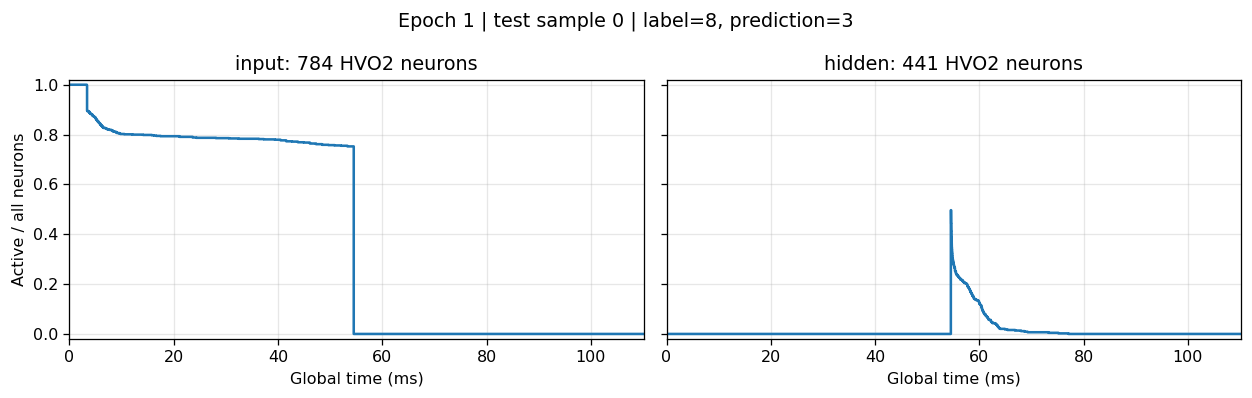

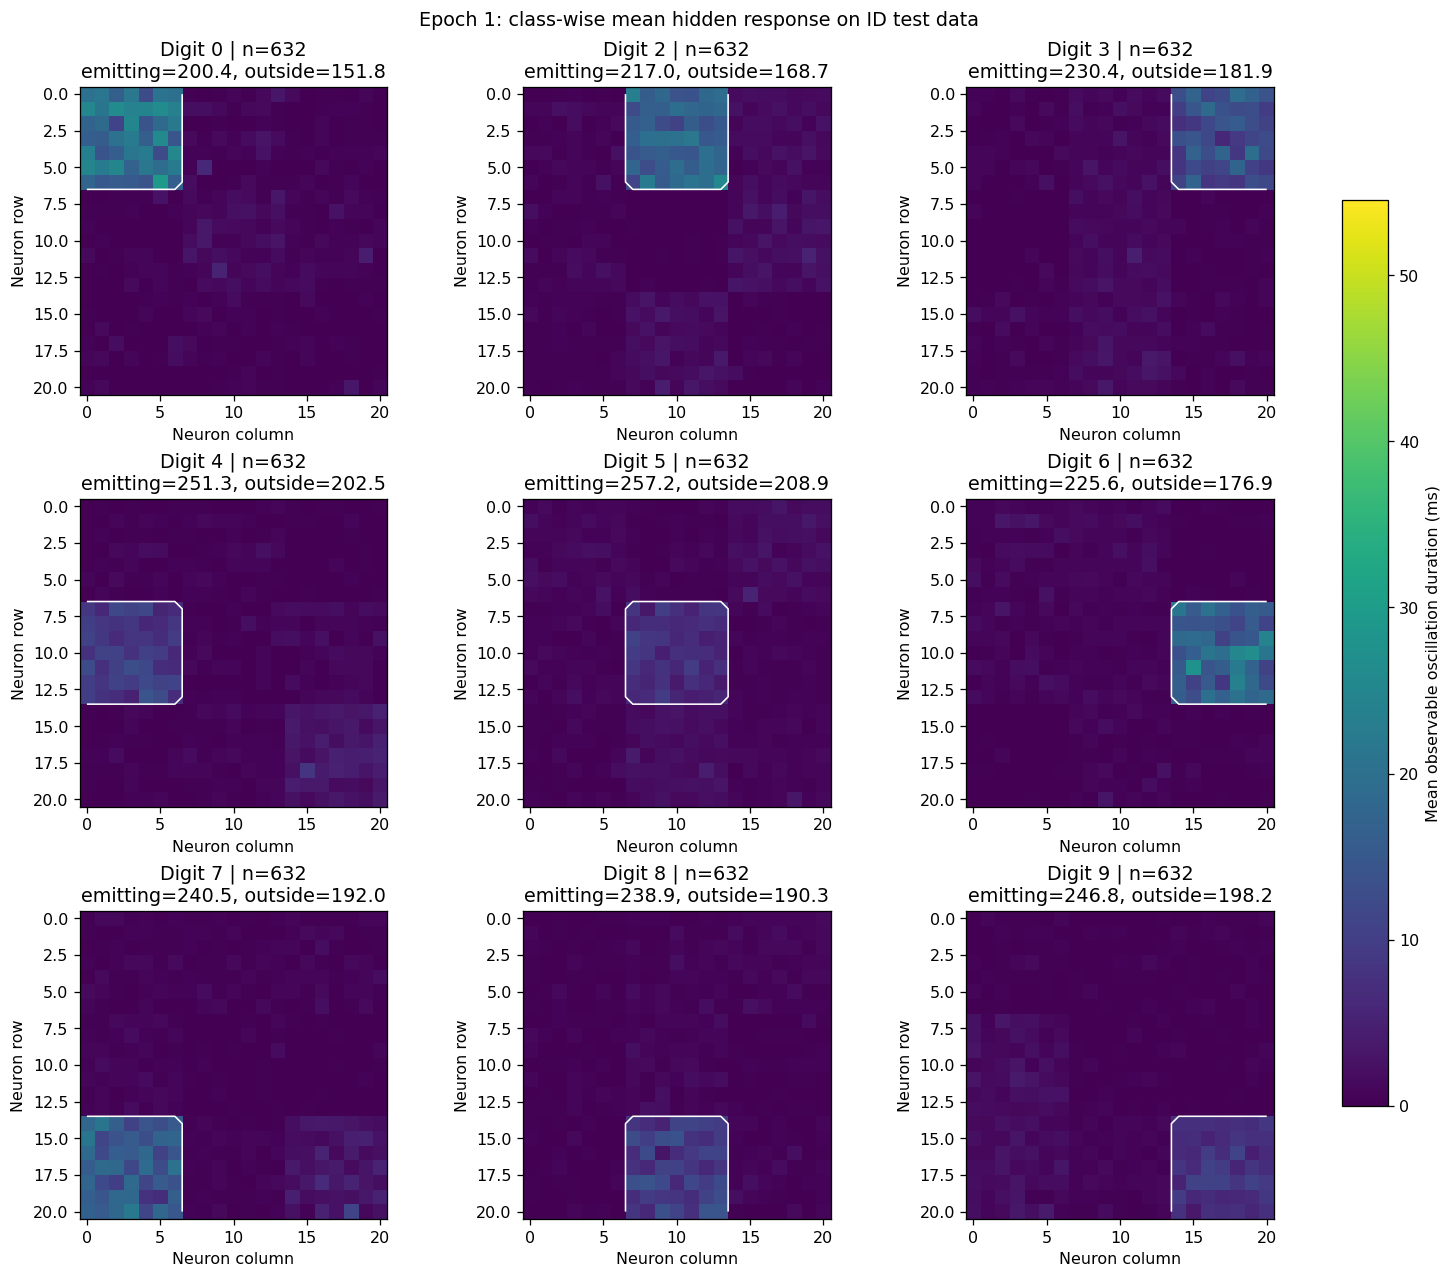

Epoch 2/5 | 训练准确率 96.37% | 测试准确率 94.92% | 分类CE 0.132328/0.174386 | 区域损失 3.9992/3.9878 | 组合损失 0.5323/0.5732 | λ=0.100 | 6.1s
  测试响应：区内/区外 20.147/0.74150 ms | 发脉冲 192.8/441（区外 144.3） | 目标区时间占比 71.79%


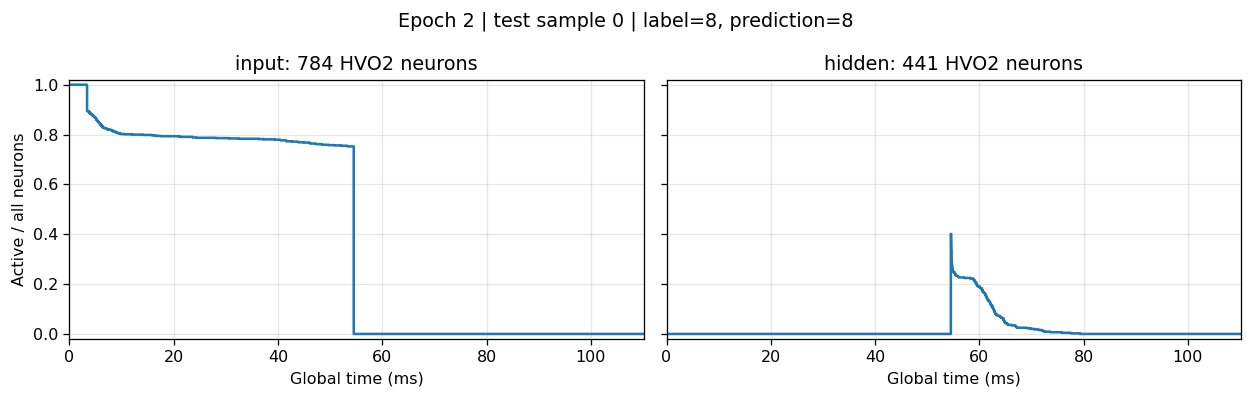

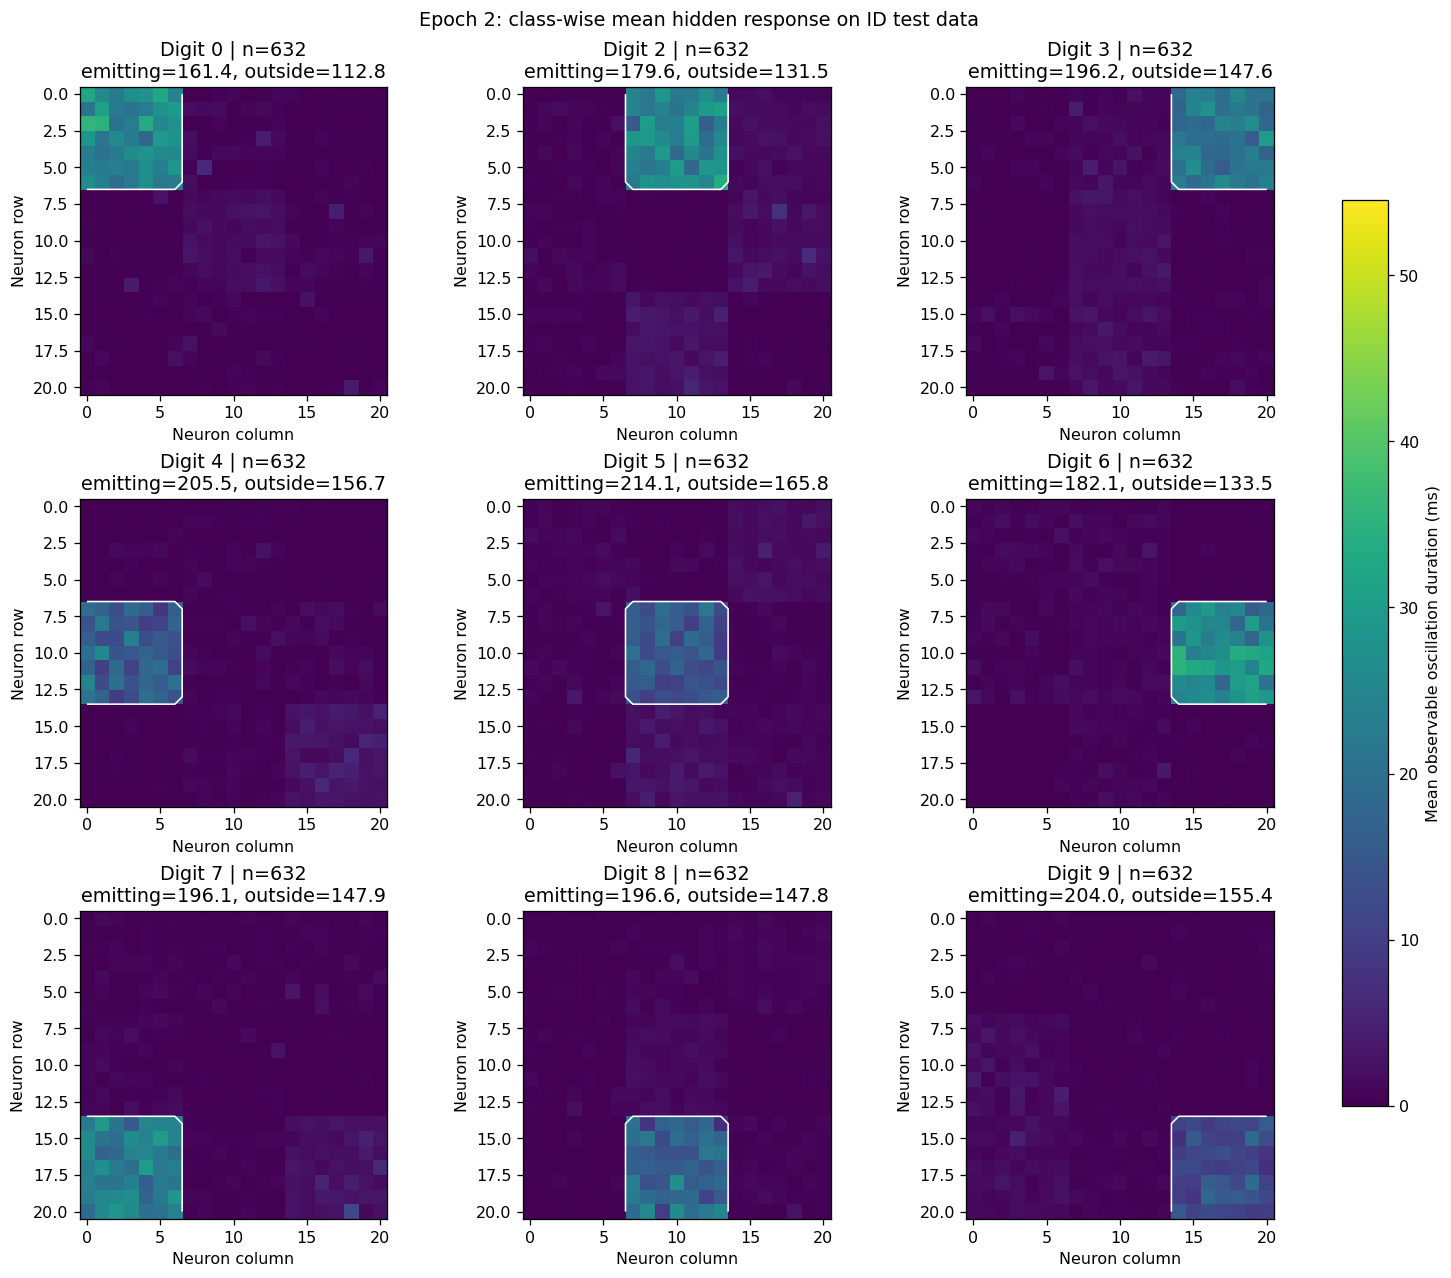

Epoch 3/5 | 训练准确率 97.26% | 测试准确率 95.45% | 分类CE 0.102617/0.155065 | 区域损失 3.6804/3.6712 | 组合损失 0.4707/0.5222 | λ=0.100 | 6.1s
  测试响应：区内/区外 23.317/0.73907 ms | 发脉冲 172.5/441（区外 124.0） | 目标区时间占比 74.74%


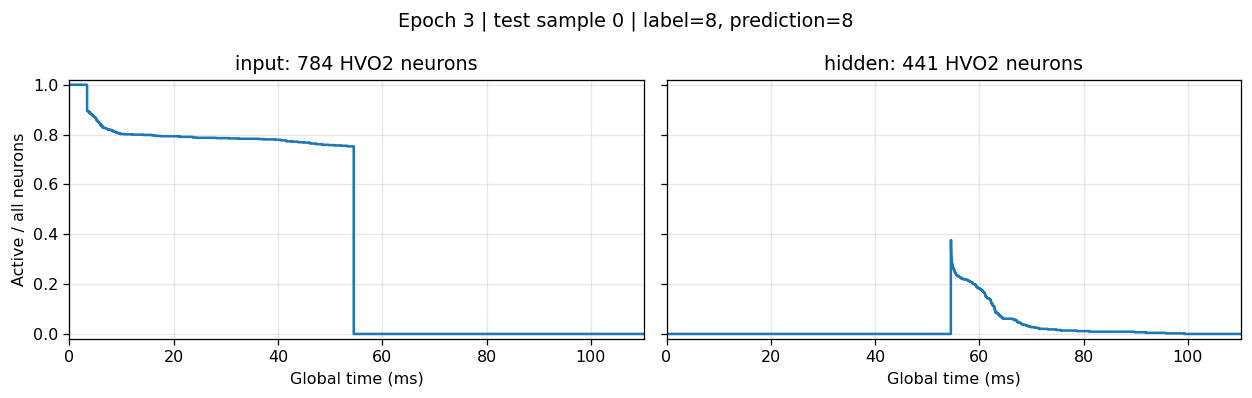

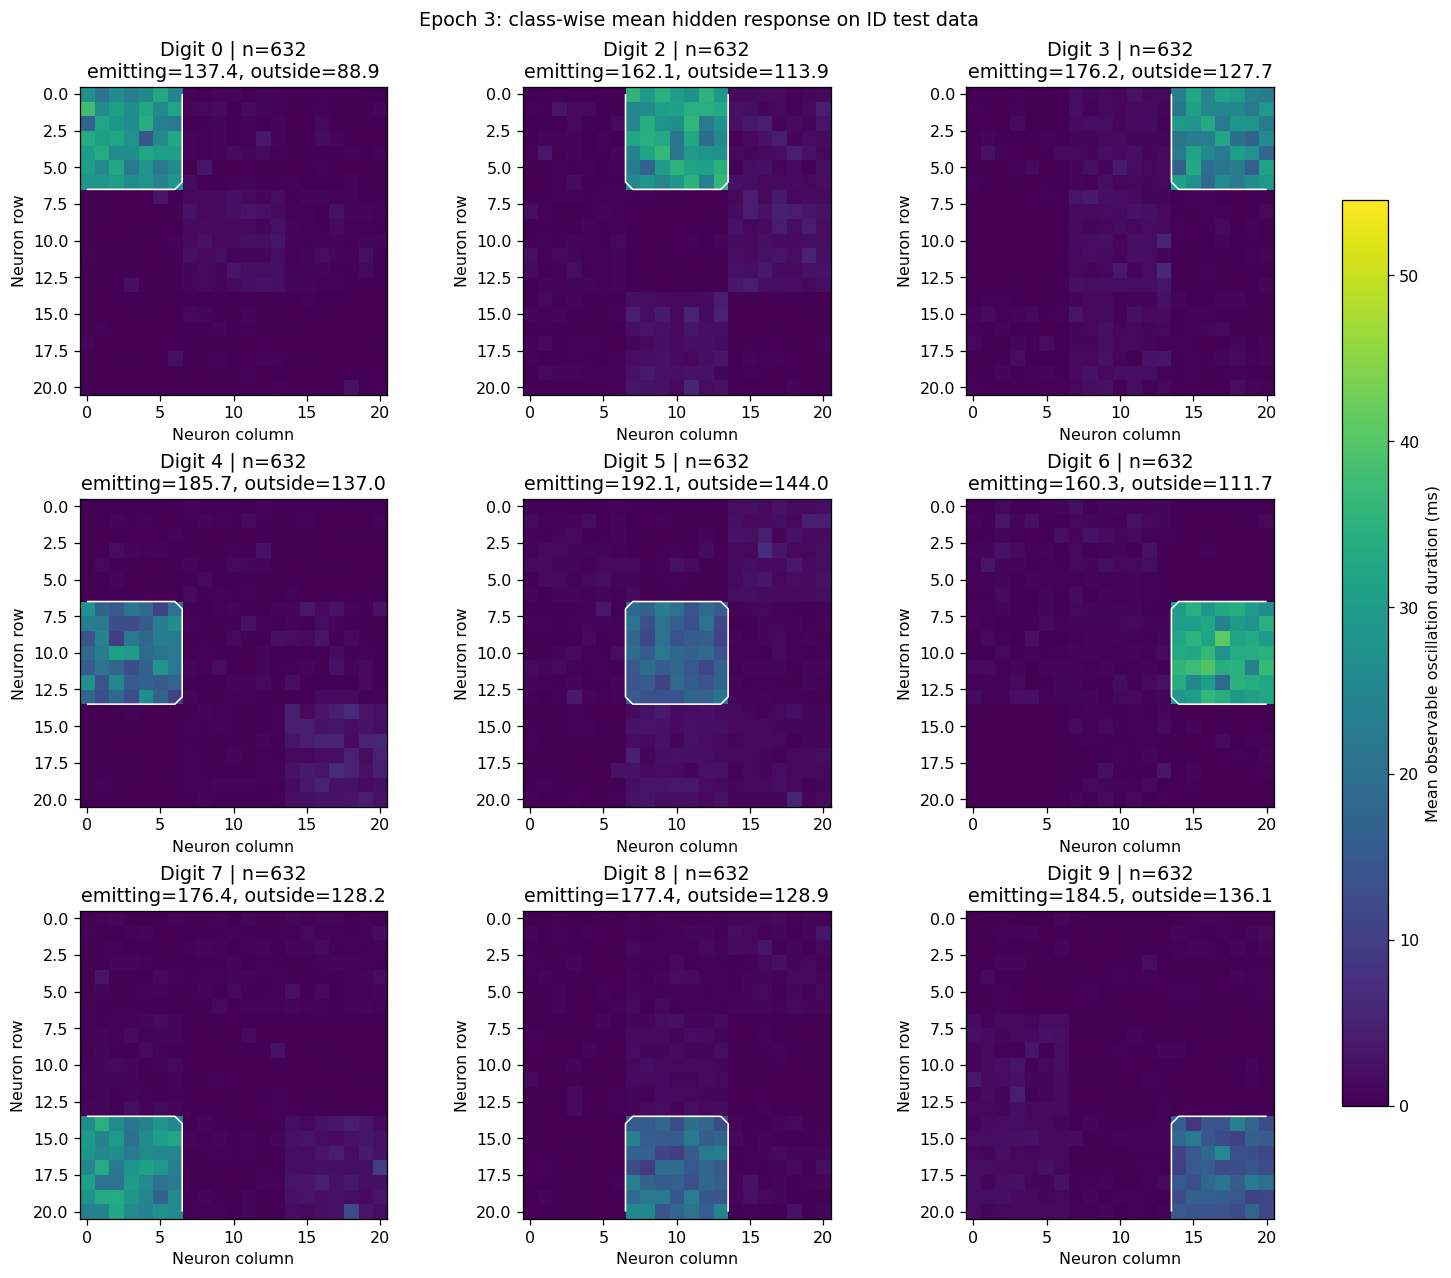

Epoch 4/5 | 训练准确率 97.80% | 测试准确率 95.55% | 分类CE 0.084389/0.148463 | 区域损失 3.5008/3.5094 | 组合损失 0.4345/0.4994 | λ=0.100 | 6.0s
  测试响应：区内/区外 25.686/0.75666 ms | 发脉冲 163.8/441（区外 115.4） | 目标区时间占比 76.31%


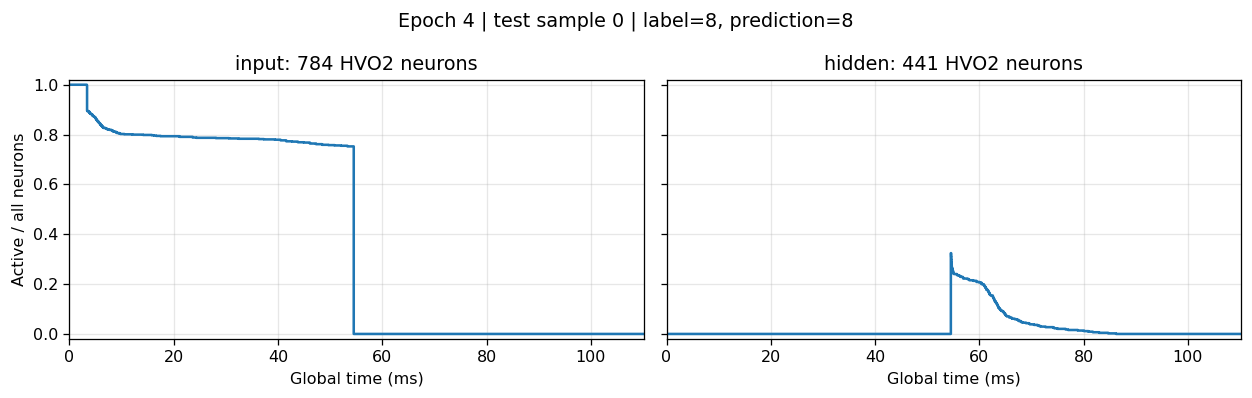

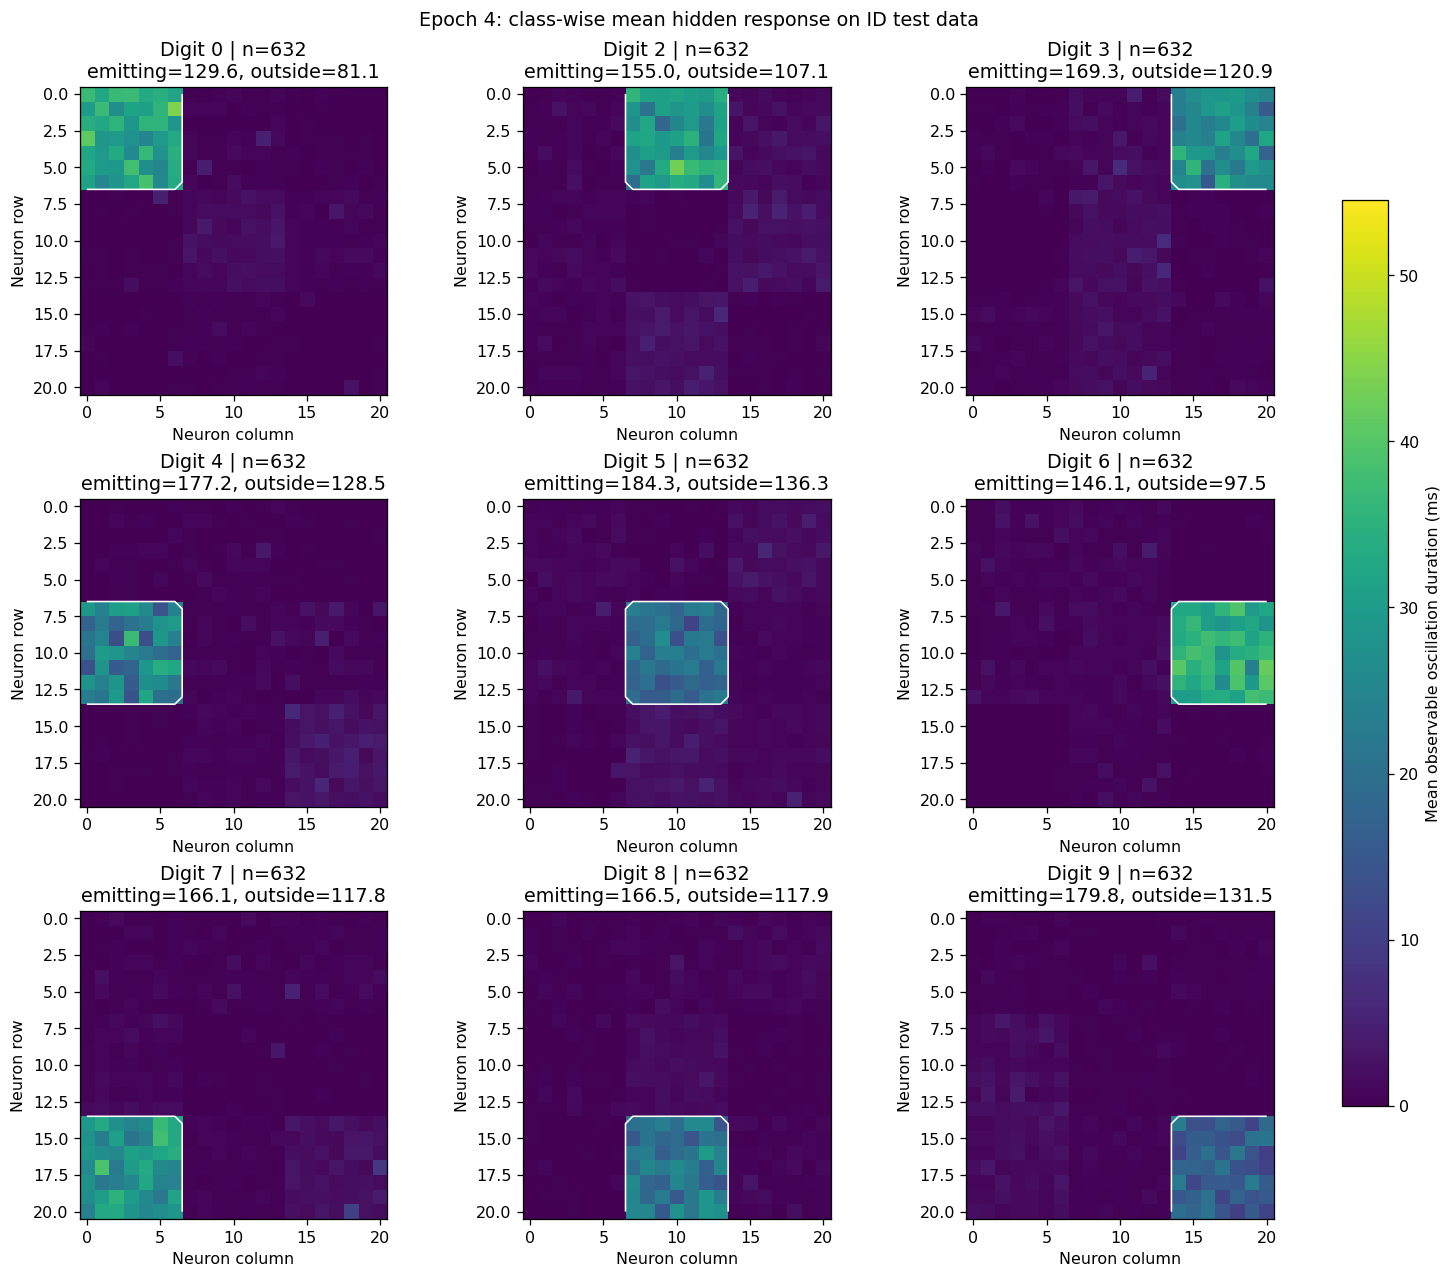

Epoch 5/5 | 训练准确率 98.18% | 测试准确率 95.50% | 分类CE 0.069120/0.148111 | 区域损失 3.3961/3.4006 | 组合损失 0.4087/0.4882 | λ=0.100 | 6.0s
  测试响应：区内/区外 26.686/0.74480 ms | 发脉冲 154.2/441（区外 105.9） | 目标区时间占比 77.56%


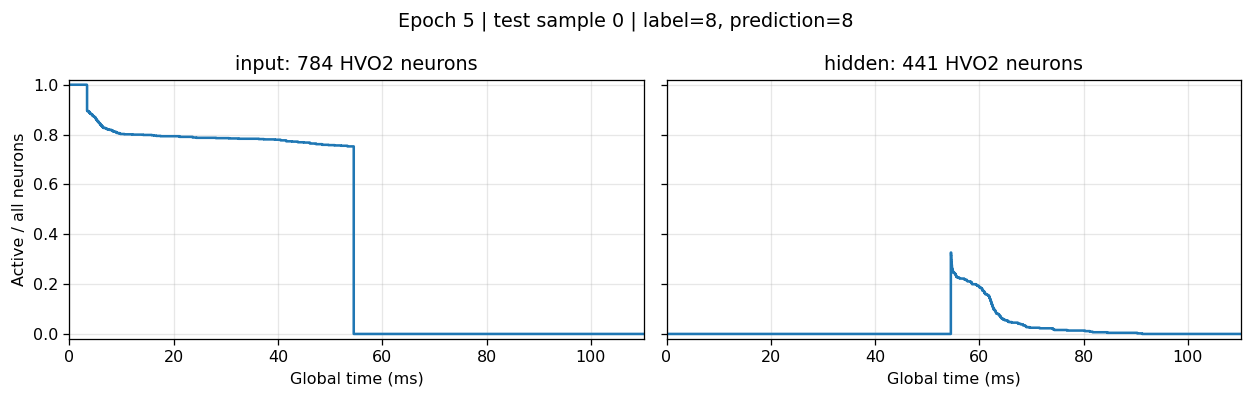

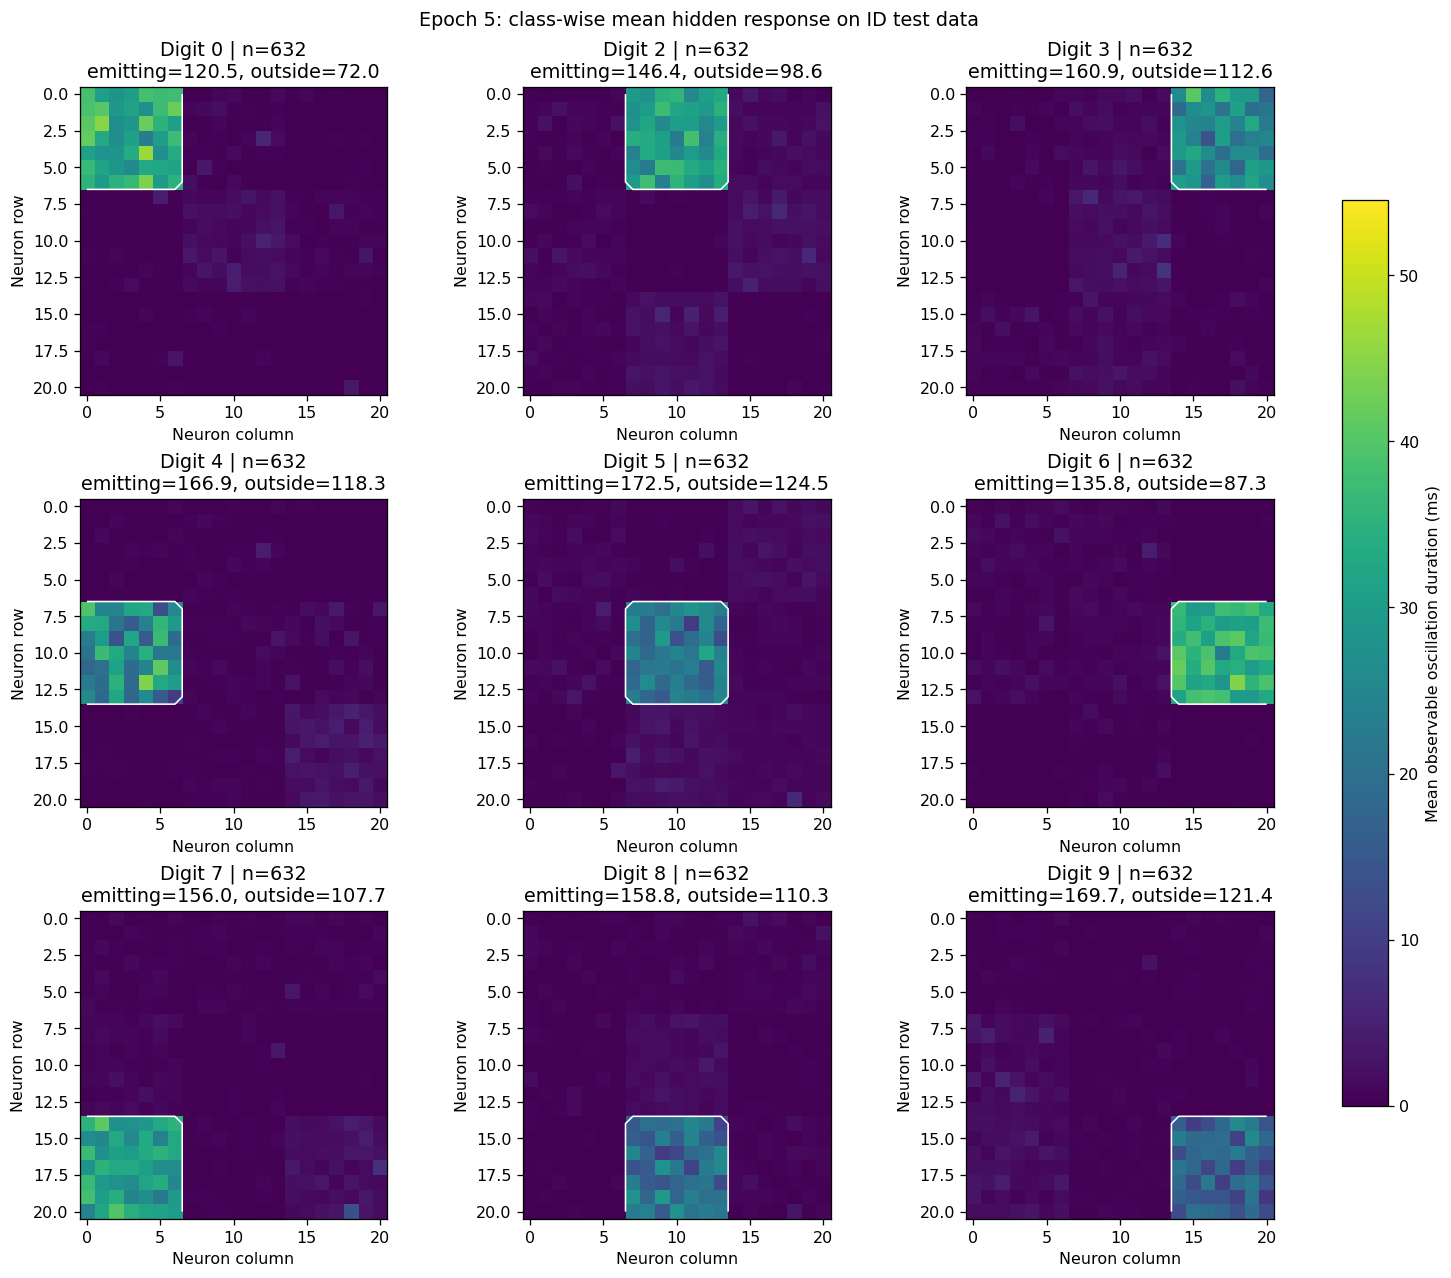

训练完成，保留第 5 轮权重。


In [3]:
seed_everything(RANDOM_SEED)
model = SparseHVO2Network().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
train_loader = make_loader(train_data, shuffle=True)
history, activity_history, heatmap_history = [], [], []
completed_epochs = 0

if RUN_TRAINING:
    for epoch in range(1, EPOCHS + 1):
        started_at = time.perf_counter()
        code_weight = TAC_LOSS_WEIGHT * min(1.0, epoch / max(1, TAC_WARMUP_EPOCHS))
        model.train()
        optimization_loss_sum, optimization_count = 0.0, 0
        for images, targets in train_loader:
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits, aux = model(image_batch(images), return_aux=True)
            classification_loss = criterion(logits, targets)
            code_loss = region_loss(aux, targets, model.class_regions).mean()
            loss = classification_loss + code_weight * code_loss
            if not torch.isfinite(loss):
                raise FloatingPointError('训练损失出现 NaN/Inf，请检查配置。')
            loss.backward()
            optimizer.step()
            optimization_loss_sum += loss.item() * len(targets)
            optimization_count += len(targets)

        train_metrics = evaluate(model, train_eval_loader, code_weight=code_weight)
        test_metrics = evaluate(model, test_loader, trace_sample_ids=HEATMAP_TEST_SAMPLE_IDS,
                                code_weight=code_weight,
                                collect_classes=HEATMAP_SAMPLE_OCCURRENCE == 'mean')
        row = {'epoch': epoch, 'code_weight': code_weight,
               'optimization_loss': optimization_loss_sum / optimization_count,
               'seconds': time.perf_counter() - started_at}
        for prefix_name, metrics in (('train', train_metrics), ('test', test_metrics)):
            for key, value in metrics.items():
                if key not in ('sample_traces', 'sample_predictions', 'classes'):
                    row[prefix_name + '_' + key] = value
        history.append(row)
        completed_epochs = epoch
        print(f"Epoch {epoch}/{EPOCHS} | 训练准确率 {row['train_accuracy']:.2%} "
              f"| 测试准确率 {row['test_accuracy']:.2%} | 分类CE {row['train_loss']:.6f}/{row['test_loss']:.6f} "
              f"| 区域损失 {row['train_code_loss']:.4f}/{row['test_code_loss']:.4f} "
              f"| 组合损失 {row['train_total_loss']:.4f}/{row['test_total_loss']:.4f} "
              f"| λ={code_weight:.3f} | {row['seconds']:.1f}s", flush=True)
        print(f"  测试响应：区内/区外 {row['test_inside_ms']:.3f}/{row['test_outside_ms']:.5f} ms "
              f"| 发脉冲 {row['test_emitted_count']:.1f}/441（区外 {row['test_outside_emitted_count']:.1f}） "
              f"| 目标区时间占比 {row['test_time_share']:.2%}", flush=True)
        activity_history.append(plot_sample_activity(model, epoch))
        if HEATMAP_SAMPLE_OCCURRENCE == 'mean':
            heatmap_history.append(plot_class_mean_durations(test_metrics['classes'], epoch=epoch))
        else:
            heatmap_history.append(plot_epoch_sample_heatmaps(
                test_metrics['sample_traces'], test_metrics['sample_predictions'], epoch))
    model.eval()
    print(f'训练完成，保留第 {completed_epochs} 轮权重。')
else:
    print('RUN_TRAINING=False，已跳过训练。')


## 3. 网络测试

第一个代码单元只测试当前ID标签，使用最后一轮权重；测试均值热力图只作展示，不用于建立原型或阈值。

第二个代码单元保持权重固定，不添加SAE：

1. 仅从实际参加训练的ID样本，按真实训练标签求441维可观测振荡时长均值，建立类别原型。当前ID是0、2–9；未知是1，均由`EXCLUDED_DIGITS`及其补集自动决定。
2. 样本只与分类头预测类别的原型求余弦。高分ID，不使用真实测试标签选原型，不取九类相似度最大值。
3. 只用独立ID校准分数确定τ，先验目标`OOD_ID_RETENTION=0.80`，取下侧20%分位数。未知样本不用于训练、原型或阈值选择。`OOD_COSINE_THRESHOLD`可手动覆盖。
4. 各标签先向最少类别下采样，再按同一比例划分。当前每个ID类别训练5,050、校准631、测试632张；9个ID总训练45,450、校准5,679、测试5,688张。
5. τ固定后，未知标签从独立测试分区取与单个ID测试类别相同数量：当前未知1取632张，与ID合计6,320张，10个测试标签各632张，未知恰好占10%。不再按未知原始数量的固定比例抽取。

**ID-only阈值规则：**

\[
\tau=\widehat Q_{\mathrm{ID\ calibration}}(1-r),\quad r=0.80,\qquad
\widehat P(s\ge\tau\mid\mathrm{ID\ calibration})\ge 0.80.
\]

实现为`np.quantile(id_scores, 1-OOD_ID_RETENTION, method='lower')`。有限样本与同分情况可能使保留率略高于目标，最终测试ID不保证恰好80%通过。`score < τ`判未知，否则保留分类头预测。

平衡下采样、候选/测试划分和ID校准均使用按数字固定的独立种子；更换未知标签时，仍参与实验的同一数字保持原下采样集合及预留测试集合。标签不通过复制样本补齐。调试子集也向下取整保持各ID等量，未知测试数量自动匹配实际使用的单类ID测试数量。

校准图只显示ID分数与保留率；测试图的ID/未知图例从参数自动生成。数据划分、阈值、训练及未知评估严格分开。

主指标定义：**保留后预测准确度 = 保留且正确分类的ID样本数 / 所有保留样本数**，因此漏检且被保留的未知样本计为错误。**未知精确率 = 判为未知且实际为OOD的样本数 / 所有判为未知的样本数**。另报未知召回率、保留ID分类准确率、ID保留率、覆盖率、AUROC及计数，防止单个指标掩盖误拒或漏检。分母为0时显示N/A。

ID/未知检测用2×2混淆热力图展示，行是真实身份、列是预测身份，**每个预测列独立归一化到100%**。左列为“ID精确率、未知漏检占比”，分母是全部判ID（保留）的样本；右列为“ID被误拒占比、未知精确率”，分母是全部判未知（拒绝）的样本。因此这里的漏检/误拒是各预测组内的占比，与以真实类别总数为分母的漏检率/误拒率不同。ID精确率只检查已知身份，不检查具体数字是否分类正确；与主要预测准确度不同。**未知召回率单独输出，二分类检测准确率暂不显示**（内存中仍保留该指标）。原始计数和百分比矩阵保存在`ood_results["confusion_matrix"]`。

全部逐样本余弦分数、9类相似度和判决留在`ood_results`；控制台只预览指定行数。图中显示ID/未知分数分布、固定阈值及ROC，不根据这些测试结果重新选阈值。


分布内测试数字: (0, 2, 3, 4, 5, 6, 7, 8, 9) | 样本数: 5688 | 第 5 轮权重
测试准确率: 95.50% | 分类交叉熵: 0.148111
逐类实际响应：digit | allocated | emitting | outside emitting | inside ms | outside ms | region time share
    0 |        49 |   120.51 |            71.97 |    33.752 |    0.57917 | 87.27%
    2 |        49 |   146.40 |            98.60 |    30.632 |    1.06638 | 74.15%
    3 |        49 |   160.94 |           112.57 |    25.966 |    0.86867 | 73.63%
    4 |        49 |   166.90 |           118.29 |    26.151 |    0.71586 | 79.39%
    5 |        49 |   172.52 |           124.48 |    21.673 |    1.00797 | 68.53%
    6 |        49 |   135.79 |            87.30 |    34.919 |    0.50160 | 85.84%
    7 |        49 |   156.03 |           107.74 |    30.837 |    0.69405 | 79.38%
    8 |        49 |   158.80 |           110.34 |    19.602 |    0.59339 | 76.68%
    9 |        49 |   169.66 |           121.45 |    16.639 |    0.67612 | 73.11%


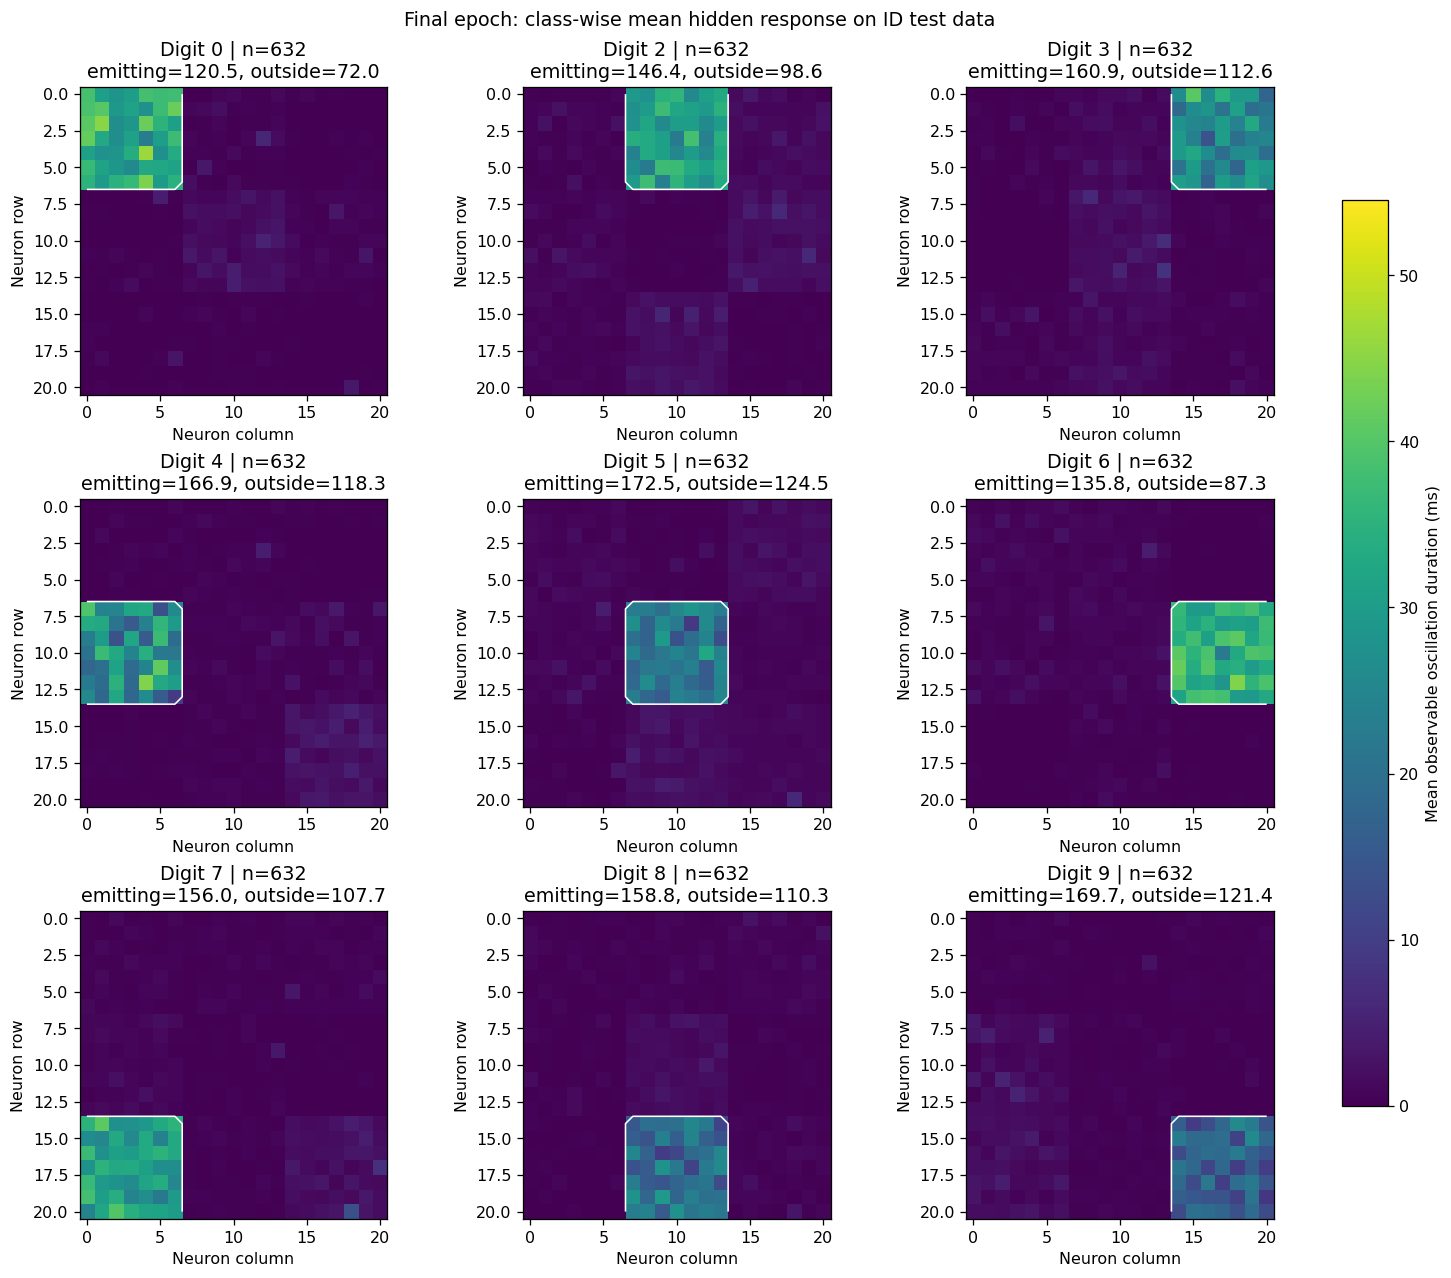

In [4]:
if completed_epochs == 0:
    raise RuntimeError('尚未训练，请先执行第2部分。')
id_test_metrics = evaluate(model, test_loader, collect_classes=True,
                           code_weight=history[-1]['code_weight'])
print(f'分布内测试数字: {TRAIN_DIGITS} | 样本数: {id_test_metrics["count"]} | 第 {completed_epochs} 轮权重')
print(f'测试准确率: {id_test_metrics["accuracy"]:.2%} | 分类交叉熵: {id_test_metrics["loss"]:.6f}')
print('逐类实际响应：digit | allocated | emitting | outside emitting | inside ms | outside ms | region time share')
for k, digit in enumerate(TRAIN_DIGITS):
    c = id_test_metrics['classes']
    print(f'{digit:>5} | {CLASS_REGION_SIZES[k]:>9} | {c["emitted_count"][k]:>8.2f} '
          f'| {c["outside_emitted_count"][k]:>16.2f} | {c["inside_ms"][k]:>9.3f} '
          f'| {c["outside_ms"][k]:>10.5f} | {c["time_share"][k]:.2%}')
plot_class_mean_durations(id_test_metrics['classes'])


原型训练样本数: 45450 | 独立ID校准: 5679 | ID测试: 5688 | OOD测试: 632
每类原型样本数: {0: 5050, 2: 5050, 3: 5050, 4: 5050, 5: 5050, 6: 5050, 7: 5050, 8: 5050, 9: 5050}
每个测试标签 632 张 | 未知占比: 10.00%
余弦阈值 τ=0.778325 | 来源: ID-only retention calibration | 校准ID保留率: 80.01%
先验ID目标保留率: 80.00%（仅ID校准；未知数字(1,)仅最终测试）
保留后预测准确度（包含漏检未知样本）: 94.86%
未知召回率（真实未知中检出的比例）: 71.68%
保留ID分类准确率: 98.53% | ID保留率: 81.28% | 全部样本保留率: 75.98%
OOD AUROC: 86.76% | 含未知的整体正确率: 79.24%
逐样本预览：source_id | true | head | cosine(predicted class) | final
    13081 |    0 |    2 |                0.405420 | 未知
    38514 |    6 |    6 |                0.991645 | 6
    64656 |    2 |    2 |                0.457287 | 未知
    16131 |    6 |    6 |                0.991572 | 6
    30256 |    3 |    3 |                0.589410 | 未知
    20006 |    5 |    5 |                0.745890 | 未知
    42114 |    3 |    3 |                0.777405 | 未知
    28112 |    2 |    2 |                0.837551 | 2
    50223 |    5 |    5 |                0.348367 | 未知
    51511 |    5 

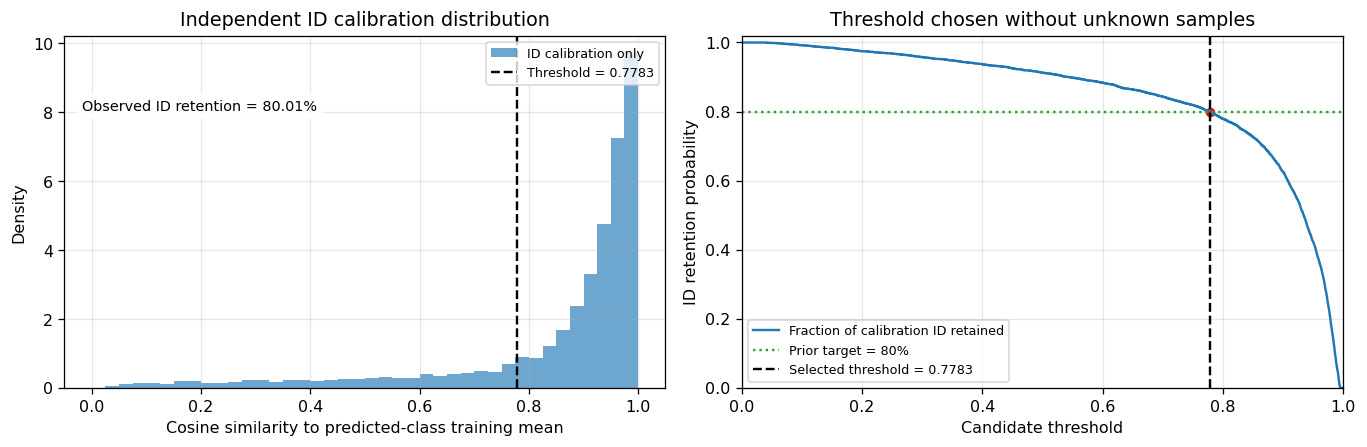

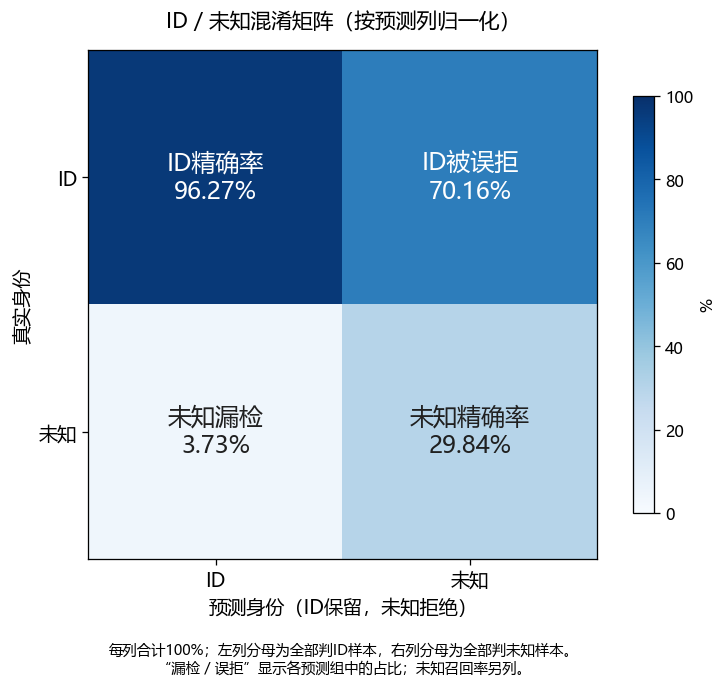

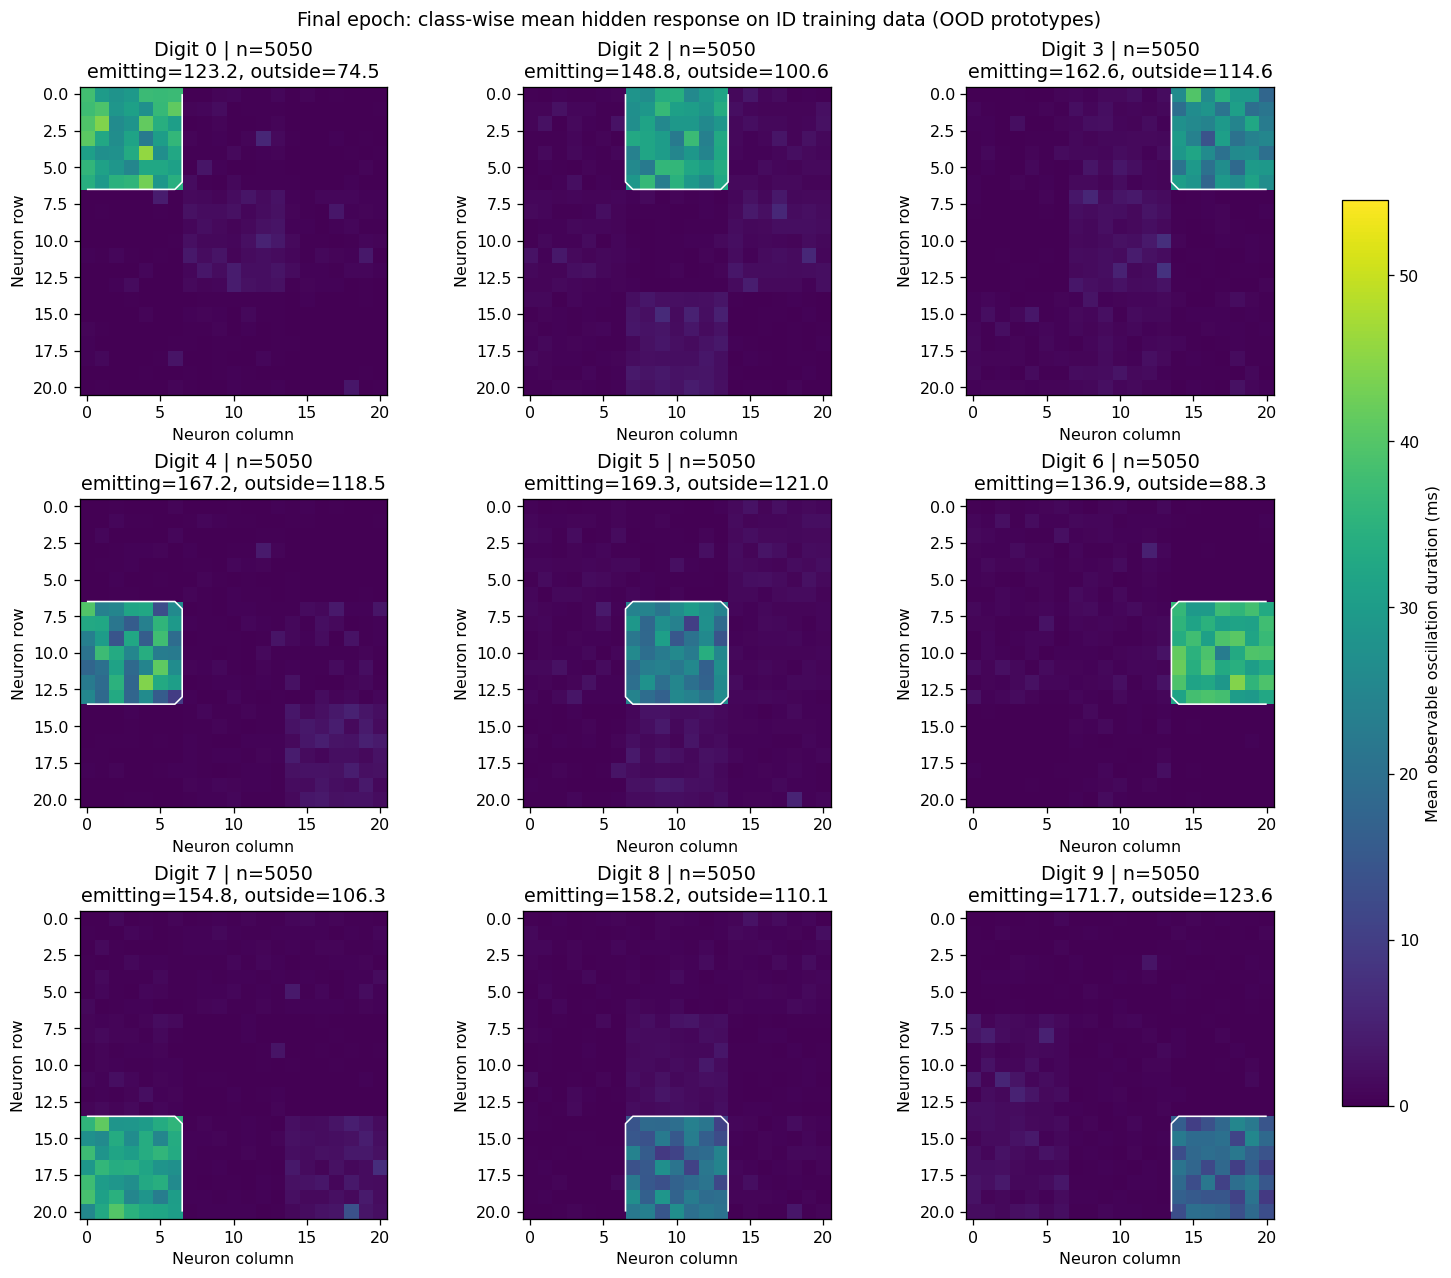

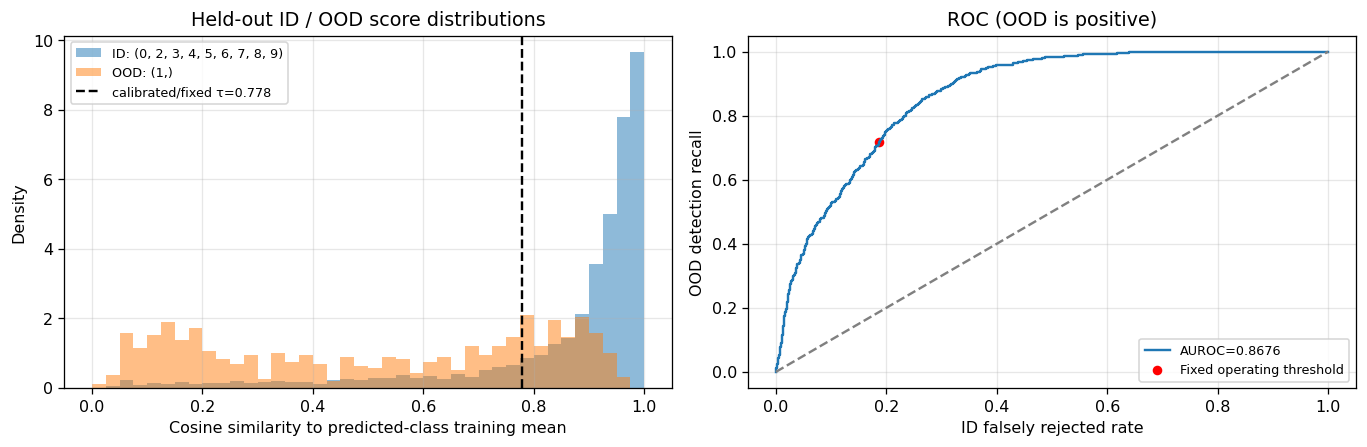

In [5]:
# 余弦OOD：原型、阈值和最终测试严格分开；此单元不执行训练或更新权重。
if completed_epochs == 0:
    raise RuntimeError('请先完成第2部分训练。')
validate_ood_configuration()


def duration_cosine_scores(response_ms, class_means_ms, predicted_indices):
    """先分别L2归一化再点积；仅取分类头预测类别列。全零响应分数为0。"""
    h = response_ms.to(dtype=torch.float64)
    means = class_means_ms.to(device=h.device, dtype=h.dtype)
    h_unit = F.normalize(h, p=2, dim=1, eps=OOD_COSINE_EPS)
    means_unit = F.normalize(means, p=2, dim=1, eps=OOD_COSINE_EPS)
    all_similarities = (h_unit @ means_unit.T).clamp(-1.0, 1.0)
    selected = all_similarities.gather(1, predicted_indices.long().reshape(-1, 1)).squeeze(1)
    return selected, all_similarities


@torch.no_grad()
def collect_ood_scores(dataset, class_means_ms):
    was_training = model.training
    model.eval()
    scores, predictions, similarities = [], [], []
    for images, _unused_targets in make_loader(dataset):
        # 不读取标签来选择比较原型；OOD数据的内部标签为-1也不会进入分类损失。
        logits, aux = model(image_batch(images), return_aux=True)
        predicted = logits.argmax(1)
        observed_duration = aux['duration_ms'] * aux['emitted']
        score, all_scores = duration_cosine_scores(observed_duration, class_means_ms, predicted)
        scores.append(score.cpu().numpy())
        predictions.append(predicted.cpu().numpy())
        similarities.append(all_scores.cpu().numpy())
    model.train(was_training)
    if not scores:
        raise ValueError('不能对空数据集计算OOD分数。')
    return {'cosine_score': np.concatenate(scores), 'predicted_index': np.concatenate(predictions),
            'all_class_cosine': np.concatenate(similarities)}


def choose_ood_threshold(id_calibration_scores):
    """只接收ID校准分数；先验ID保留比例和可选手动阈值是唯一阈值参数。"""
    values = np.asarray(id_calibration_scores, dtype=float)
    if values.ndim != 1 or values.size == 0 or not np.isfinite(values).all():
        raise ValueError('ID校准分数必须是一维、非空且全部有限。')
    if OOD_COSINE_THRESHOLD is None:
        # 取下侧经验分位数；score >= threshold保留，校准保留率至少达到目标。
        quantile = 1.0 - OOD_ID_RETENTION
        threshold = float(np.quantile(values, quantile, method='lower'))
        source = 'ID-only retention calibration'
    else:
        quantile = None
        threshold = float(OOD_COSINE_THRESHOLD)
        source = 'manual override'
    diagnostics = {'method': 'id_retention' if quantile is not None else 'manual',
                   'n_id': len(values), 'target_id_retention': OOD_ID_RETENTION,
                   'quantile': quantile,
                   'id_retention': float(np.mean(values >= threshold)),
                   'id_false_rejection': float(np.mean(values < threshold))}
    return threshold, source, diagnostics


def plot_id_calibration(id_scores, threshold, diagnostics):
    # 图中只有独立ID校准分数；直方图分箱不影响阈值。
    values = np.sort(np.asarray(id_scores, dtype=float))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    bins = np.linspace(0, 1, OOD_HIST_BINS + 1)
    axes[0].hist(values, bins=bins, density=True, alpha=0.65, label='ID calibration only')
    axes[0].axvline(threshold, color='black', linestyle='--', label=f'Threshold = {threshold:.4f}')
    axes[0].text(0.03, 0.82, f"Observed ID retention = {diagnostics['id_retention']:.2%}",
                 transform=axes[0].transAxes, va='top', fontsize=9,
                 bbox=dict(facecolor='white', alpha=0.85, edgecolor='none'))
    axes[0].set(xlabel='Cosine similarity to predicted-class training mean', ylabel='Density',
                title='Independent ID calibration distribution')
    grid = np.unique(np.concatenate(([0.0], values, [1.0])))
    retention = 1.0 - np.searchsorted(values, grid, side='left') / len(values)
    axes[1].step(grid, retention, where='pre', label='Fraction of calibration ID retained')
    if diagnostics['method'] == 'id_retention':
        axes[1].axhline(OOD_ID_RETENTION, color='tab:green', linestyle=':',
                        label=f'Prior target = {OOD_ID_RETENTION:.0%}')
    axes[1].axvline(threshold, color='black', linestyle='--', label=f'Selected threshold = {threshold:.4f}')
    axes[1].scatter([threshold], [diagnostics['id_retention']], color='red', s=25)
    axes[1].set(xlabel='Candidate threshold', ylabel='ID retention probability', xlim=(0, 1), ylim=(0, 1.02),
                title='Threshold chosen without unknown samples')
    for index, ax in enumerate(axes):
        ax.legend(fontsize=8, loc='upper right' if index == 0 else 'lower left')
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def compute_ood_metrics(true_labels, head_predictions, cosine_scores, threshold):
    true_labels = np.asarray(true_labels)
    head_predictions = np.asarray(head_predictions)
    scores = np.asarray(cosine_scores, dtype=float)
    if true_labels.shape != head_predictions.shape or true_labels.shape != scores.shape:
        raise ValueError('OOD标签、预测和分数形状不匹配。')
    is_ood = np.isin(true_labels, EXCLUDED_DIGITS)
    is_id = np.isin(true_labels, TRAIN_DIGITS)
    if not (is_id | is_ood).all():
        raise ValueError('评估标签包含未配置的ID/OOD类别。')
    rejected = scores < threshold
    accepted = ~rejected
    tp = int((is_ood & rejected).sum())
    fp = int((is_id & rejected).sum())
    fn = int((is_ood & accepted).sum())
    tn = int((is_id & accepted).sum())
    correct_kept = int((is_id & accepted & (head_predictions == true_labels)).sum())
    def ratio(numerator, denominator):
        return numerator / denominator if denominator else float('nan')
    metrics = {
        'retained_accuracy': ratio(correct_kept, int(accepted.sum())),
        'id_precision': ratio(tn, tn + fn),  # 判ID样本中确实为ID；不检查具体数字分类
        'unknown_precision': ratio(tp, tp + fp),
        'unknown_recall': ratio(tp, tp + fn),
        'retained_id_accuracy': ratio(correct_kept, tn),
        'id_retention': ratio(tn, tn + fp),
        'coverage': float(accepted.mean()),
        'binary_detection_accuracy': ratio(tp + tn, len(scores)),
        'open_set_accuracy': ratio(correct_kept + tp, len(scores)),
        'auroc': float(roc_auc_score(is_ood.astype(int), 1.0 - scores))
                 if is_ood.any() and is_id.any() else float('nan'),
        'tp_unknown': tp, 'fp_unknown': fp, 'fn_unknown': fn, 'tn_id': tn,
        'correct_retained_id': correct_kept,
        'n_id': int(is_id.sum()), 'n_ood': int(is_ood.sum()),
        'n_retained': int(accepted.sum()), 'n_rejected': int(rejected.sum()),
    }
    return metrics, rejected, is_ood


def plot_ood_confusion(metrics):
    """行=真实身份，列=预测身份；按预测列归一化，两个对角元素是精确率。"""
    counts = np.array([[metrics['tn_id'], metrics['fp_unknown']],
                       [metrics['fn_unknown'], metrics['tp_unknown']]], dtype=np.int64)
    column_totals = counts.sum(axis=0, keepdims=True)
    percentages = np.divide(counts * 100.0, column_totals,
                            out=np.full((2, 2), np.nan), where=column_totals > 0)
    available_fonts = {font.name for font in font_manager.fontManager.ttflist}
    chinese_font = next((name for name in ('Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC',
                                          'Arial Unicode MS') if name in available_fonts), None)
    names = ([['ID精确率', 'ID被误拒'], ['未知漏检', '未知精确率']] if chinese_font else
             [['ID precision', 'ID falsely rejected'], ['Unknown missed', 'Unknown precision']])
    labels = ['ID', '未知'] if chinese_font else ['ID', 'Unknown']
    style = {'font.family': chinese_font or 'DejaVu Sans', 'axes.unicode_minus': False}
    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=(7.2, 6.0))
        ax.set_facecolor('#eeeeee')
        image = ax.imshow(np.ma.masked_invalid(percentages), cmap='Blues', vmin=0, vmax=100)
        ax.set_xticks([0, 1], labels=labels, fontsize=12)
        ax.set_yticks([0, 1], labels=labels, fontsize=12)
        ax.set_xlabel('预测身份（ID保留，未知拒绝）' if chinese_font else 'Predicted identity', fontsize=12)
        ax.set_ylabel('真实身份' if chinese_font else 'True identity', fontsize=12)
        ax.set_title('ID / 未知混淆矩阵（按预测列归一化）' if chinese_font else
                     'ID / unknown confusion matrix (column-normalized)', fontsize=13, pad=14)
        for row in range(2):
            for col in range(2):
                value = percentages[row, col]
                label = f'{value:.2f}%' if np.isfinite(value) else 'N/A'
                ax.text(col, row, f'{names[row][col]}\n{label}', ha='center', va='center',
                        fontsize=15, color='white' if np.isfinite(value) and value >= 60 else '#202020')
        fig.colorbar(image, ax=ax, shrink=0.82, label='%' )
        note = ('每列合计100%；左列分母为全部判ID样本，右列分母为全部判未知样本。\n'
                '“漏检 / 误拒”显示各预测组中的占比；未知召回率另列。' if chinese_font else
                'Each column sums to 100%; denominator = all predictions in that column.\n'
                'Missed / falsely rejected cells are shares within predicted groups; recall is separate.')
        fig.text(0.5, 0.025, note, ha='center', va='bottom', fontsize=9)
        fig.tight_layout(rect=(0, 0.10, 1, 1))
        plt.show()
        plt.close(fig)
    return {'counts': counts, 'percentages': percentages, 'normalization': 'predicted_column',
            'row_labels': ('ID', 'unknown'), 'column_labels': ('ID', 'unknown')}


# 数据隔离审计：训练/原型、校准、ID测试两两不相交，且三者均不含排除数字。
for left, right in ((train_indices, calibration_indices), (train_indices, test_indices),
                    (calibration_indices, test_indices)):
    if np.intersect1d(left.numpy(), right.numpy()).size:
        raise RuntimeError('训练、校准和测试索引存在交叠。')
for indices in (train_indices, calibration_indices, test_indices):
    if not torch.isin(all_labels[indices].long(), torch.tensor(TRAIN_DIGITS)).all():
        raise RuntimeError('ID分区混入了排除数字。')

# 只用真正参加权重训练的train_data构建原型；不复用id_test_metrics中的测试均值。
prototype_metrics = evaluate(model, train_eval_loader, collect_classes=True)
prototype_class_results = prototype_metrics['classes']
ood_prototypes_ms = torch.as_tensor(prototype_class_results['mean_duration_ms'],
                                    dtype=torch.float64, device=DEVICE)
if (prototype_class_results['counts'] <= 0).any() or (ood_prototypes_ms.norm(dim=1) <= OOD_COSINE_EPS).any():
    raise RuntimeError('有类别缺少训练样本或平均响应为全零，无法建立有效余弦原型。')
ood_prototype_source_indices = train_indices.clone()

# 先只用独立ID校准并固定阈值；此时尚未构造/评分任何未知样本。
ood_calibration_scores = collect_ood_scores(calibration_data, ood_prototypes_ms)
ood_threshold, ood_threshold_source, ood_calibration_diagnostics = choose_ood_threshold(
    ood_calibration_scores['cosine_score'])
ood_calibration_retention = ood_calibration_diagnostics['id_retention']

# 阈值固定之后才构造未知测试；每个未知标签的数量等于单个ID标签的测试数量。
id_test_counts = [int((all_labels[test_indices] == d).sum()) for d in TRAIN_DIGITS]
if len(set(id_test_counts)) != 1 or id_test_counts[0] < 1:
    raise RuntimeError('ID测试各标签必须等量且非空，才能构造等量未知测试。')
ood_per_class_count = id_test_counts[0]
ood_parts = []
sample_generator = torch.Generator().manual_seed(OOD_SAMPLE_SEED)
for digit in EXCLUDED_DIGITS:
    candidates = balance_info['test_indices'][digit]
    if len(candidates) < ood_per_class_count:
        raise ValueError(f'未知数字 {digit} 的独立测试分区不足以匹配单个ID类别。')
    digit_generator = torch.Generator().manual_seed(OOD_SAMPLE_SEED + 1009 * digit)
    order = torch.randperm(len(candidates), generator=digit_generator)
    ood_parts.append(candidates[order[:ood_per_class_count]])
if not ood_parts:
    raise ValueError('需要配置至少一个EXCLUDED_DIGITS数字进行OOD评估。')
ood_test_indices = torch.cat(ood_parts)
mixed_test_indices = torch.cat((test_indices, ood_test_indices))
mixed_test_indices = mixed_test_indices[torch.randperm(len(mixed_test_indices), generator=sample_generator)]
ood_mixed_data = make_dataset(mixed_test_indices)
mixed_scores = collect_ood_scores(ood_mixed_data, ood_prototypes_ms)
mixed_true_labels = all_labels[mixed_test_indices].numpy()
mixed_head_predictions = np.asarray(TRAIN_DIGITS)[mixed_scores['predicted_index']]
ood_metrics, ood_rejected, mixed_is_ood = compute_ood_metrics(
    mixed_true_labels, mixed_head_predictions, mixed_scores['cosine_score'], ood_threshold)

ood_results = {
    'source_id': mixed_test_indices.numpy().copy(), 'true_label': mixed_true_labels,
    'head_prediction': mixed_head_predictions, 'cosine_score': mixed_scores['cosine_score'],
    'all_class_cosine': mixed_scores['all_class_cosine'], 'is_ood': mixed_is_ood,
    'predicted_unknown': ood_rejected,
    'final_prediction': np.where(ood_rejected, -1, mixed_head_predictions),  # -1表示未知
    'threshold': ood_threshold, 'threshold_source': ood_threshold_source, 'metrics': ood_metrics,
    'calibration_diagnostics': ood_calibration_diagnostics,
}

def percent_or_na(value):
    return f'{value:.2%}' if np.isfinite(value) else 'N/A（分母为0或无两类样本）'

print(f'原型训练样本数: {len(train_data)} | 独立ID校准: {len(calibration_data)} '
      f'| ID测试: {ood_metrics["n_id"]} | OOD测试: {ood_metrics["n_ood"]}')
print('每类原型样本数:', dict(zip(TRAIN_DIGITS, prototype_class_results['counts'].astype(int))))
print(f'每个测试标签 {ood_per_class_count} 张 | 未知占比: {mixed_is_ood.mean():.2%}')
print(f'余弦阈值 τ={ood_threshold:.6f} | 来源: {ood_threshold_source} '
      f'| 校准ID保留率: {ood_calibration_retention:.2%}')
print(f'先验ID目标保留率: {OOD_ID_RETENTION:.2%}（仅ID校准；未知数字{EXCLUDED_DIGITS}仅最终测试）')
print(f'保留后预测准确度（包含漏检未知样本）: {percent_or_na(ood_metrics["retained_accuracy"])}')
print(f'未知召回率（真实未知中检出的比例）: {percent_or_na(ood_metrics["unknown_recall"])}')
print(f'保留ID分类准确率: {percent_or_na(ood_metrics["retained_id_accuracy"])} '
      f'| ID保留率: {percent_or_na(ood_metrics["id_retention"])} '
      f'| 全部样本保留率: {percent_or_na(ood_metrics["coverage"])}')
print(f'OOD AUROC: {percent_or_na(ood_metrics["auroc"])} '
      f'| 含未知的整体正确率: {percent_or_na(ood_metrics["open_set_accuracy"])}')
print('逐样本预览：source_id | true | head | cosine(predicted class) | final')
for i in range(min(OOD_PREVIEW_ROWS, len(mixed_true_labels))):
    decision = '未知' if ood_rejected[i] else str(mixed_head_predictions[i])
    print(f'{int(mixed_test_indices[i]):>9} | {int(mixed_true_labels[i]):>4} '
          f'| {int(mixed_head_predictions[i]):>4} | {mixed_scores["cosine_score"][i]:>23.6f} | {decision}')
print('全部逐样本分数及9类相似度已保存在ood_results；未知标签记为-1。')

plot_id_calibration(ood_calibration_scores['cosine_score'], ood_threshold, ood_calibration_diagnostics)

ood_results['confusion_matrix'] = plot_ood_confusion(ood_metrics)

plot_class_mean_durations(prototype_class_results, data_description='ID training data (OOD prototypes)')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, OOD_HIST_BINS + 1)
for mask, name in ((~mixed_is_ood, f'ID: {TRAIN_DIGITS}'), (mixed_is_ood, f'OOD: {EXCLUDED_DIGITS}')):
    axes[0].hist(mixed_scores['cosine_score'][mask], bins=bins, density=True, alpha=0.5, label=name)
axes[0].axvline(ood_threshold, color='black', linestyle='--', label=f'calibrated/fixed τ={ood_threshold:.3f}')
axes[0].set(xlabel='Cosine similarity to predicted-class training mean', ylabel='Density',
            title='Held-out ID / OOD score distributions')
axes[0].legend(fontsize=8)
fpr, tpr, _ = roc_curve(mixed_is_ood.astype(int), 1.0 - mixed_scores['cosine_score'])
axes[1].plot(fpr, tpr, label=f'AUROC={ood_metrics["auroc"]:.4f}')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].scatter([1 - ood_metrics['id_retention']], [ood_metrics['unknown_recall']],
                color='red', s=25, label='Fixed operating threshold')
axes[1].set(xlabel='ID falsely rejected rate', ylabel='OOD detection recall', title='ROC (OOD is positive)')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
plt.close(fig)
